# Dubai Satellite Imagery Semantic Segmentation
Humans in the Loop has published an open access dataset annotated for a joint project with the Mohammed Bin Rashid Space Center in Dubai, the UAE.

The dataset consists of aerial imagery of Dubai obtained by MBRSC satellites and annotated with pixel-wise semantic segmentation in 6 classes. The images were segmented by the trainees of the Roia Foundation in Syria.

Original Dataset Link: https://humansintheloop.org/resources/datasets/semantic-segmentation-dataset/

# Installing & Importing Libraries

In [2]:
import pickle # used for saving and loading python objects
import numpy as np # used for numerical operations
import pandas as pd # used for data manipulation and analysis
from PIL import Image # used for image processing
import albumentations as A # used for image augmentation
from IPython.display import SVG # used for displaying SVG images in Jupyter notebooks
import matplotlib.pyplot as plt # used for plotting and visualizing data
%matplotlib inline
# %matplotlib inline is used for displaying plots inline in Jupyter notebooks
import os, re, sys, random, shutil, cv2
# os: used for interacting with the operating system
# re: used for regular expressions
# sys: used for system-specific parameters and functions
# random: used for generating random numbers
# shutil: used for file operations
# cv2: used for computer vision tasks

import tensorflow as tf # used for machine learning and deep learning tasks
from tensorflow import keras # used for building and training deep learning models
from tensorflow.keras import backend as K # used for accessing the backend of Keras
from tensorflow.keras.models import Model # used for creating Keras models
from tensorflow.keras.models import Model # used for creating Keras models
from tensorflow.keras.optimizers import Adam, Nadam # used for optimization algorithms
from tensorflow.keras import applications, optimizers # used for accessing pre-trained models and optimization algorithms
from tensorflow.keras.applications import InceptionResNetV2 # used for transfer learning with the InceptionResNetV2 model
from tensorflow.keras.applications.resnet50 import preprocess_input # used for preprocessing input images for the ResNet50 model

from tensorflow.keras.preprocessing.image import ImageDataGenerator, load_img, img_to_array # used for image data augmentation and preprocessing
from tensorflow.keras.utils import model_to_dot, plot_model # used for visualizing Keras models
from tensorflow.keras.callbacks import ModelCheckpoint, ReduceLROnPlateau, EarlyStopping, CSVLogger, LearningRateScheduler # used for monitoring and controlling the training process of Keras models
from tensorflow.keras.layers import Input, Conv2D, BatchNormalization, Activation, MaxPool2D, Conv2DTranspose, Concatenate, ZeroPadding2D, Dropout # used for building custom layers in Keras models

# Data Augmentation using Albumentations Library
[Albumentations](https://albumentations.ai/) is a Python library for fast and flexible image augmentations. Albumentations efficiently implements a rich variety of image transform operations that are optimized for performance, and does so while providing a concise, yet powerful image augmentation interface for different computer vision tasks, including object classification, segmentation, and detection.

Data augmentation is done by the following techniques:

1. Random Cropping
2. Horizontal Flipping
3. Vertical Flipping
4. Rotation
5. Random Brightness & Contrast
6. Contrast Limited Adaptive Histogram Equalization (CLAHE)
7. Grid Distortion
8. Optical Distortion

In [3]:
from google.colab import drive
drive.mount('/content/drive')
dataset_root = "/content/drive/MyDrive/MBRSC dataset/Semantic segmentation dataset"

images_dir = f"{dataset_root}/Tile 1/images/"
masks_dir = f"{dataset_root}/Tile 1/masks/"

Mounted at /content/drive


In [4]:
def augment(width, height): # function to perform data augmentation on images
    transform = A.Compose([ # A.compose is used to combine multiple augmentation techniques
        A.RandomCrop(width=width, height=height, p=1.0), # Randomly crops the image to the specified width and height with a probability of 1.0
        A.HorizontalFlip(p=1.0), # Randomly flips the image horizontally with a probability of 1.0, p= 1 means that the transformation will be applied to all images
        A.VerticalFlip(p=1.0), # Randomly flips the image vertically with a probability of 1.0
        A.Rotate(limit=[60, 300], p=1.0, interpolation=cv2.INTER_NEAREST), # Randomly rotates the image within the specified limit with a probability of 1.0, using nearest neighbor interpolation means that the pixel value of the nearest neighbor will be used for the new pixel value after rotation
        A.RandomBrightnessContrast(brightness_limit=[-0.2, 0.3], contrast_limit=0.2, p=1.0), # Randomly adjusts the brightness and contrast of the image within the specified limits with a probability of 1.0
        A.OneOf([ # OneOf is used to apply one of the specified augmentations with a probability of 1.0
            A.CLAHE (clip_limit=1.5, tile_grid_size=(8, 8), p=0.5), # applies Contrast Limited Adaptive Histogram Equalization (CLAHE) to the image with a probability of 0.5 , it enhances the contrast of the image by dividing it into small tiles and applying histogram equalization to each tile
            A.GridDistortion(p=0.5), # applies grid distortion to the image with a probability of 0.5, it distorts the image by applying a grid of random displacements to the pixels
            A.OpticalDistortion(distort_limit=1, shift_limit=0.5, interpolation=cv2.INTER_NEAREST, p=0.5), # applies optical distortion to the image with a probability of 0.5, it simulates the effect of a lens distortion by applying a random displacement to the pixels based on a distortion model
        ], p=1.0),
    ], p=1.0)

    return transform

In [5]:
def visualize(image, mask, original_image=None, original_mask=None): # function to visualize the original and transformed images and masks
    fontsize = 16

    if original_image is None and original_mask is None: # if no original image and mask are provided, only the transformed image and mask will be displayed
        f, ax = plt.subplots(2, 1, figsize=(10, 10), squeeze=True) # create a figure with 2 subplots (1 row, 2 columns) and set the figure size to 10x10 inches.
        f.set_tight_layout(h_pad=5, w_pad=5) # set the tight layout of the figure with horizontal and vertical padding of 5 inches

        ax[0].imshow(image) # display the transformed image in the first subplot
        ax[1].imshow(mask) # display the transformed mask in the second subplot
    else: # if original image and mask are provided, both the original and transformed images and masks will be displayed
        f, ax = plt.subplots(2, 2, figsize=(16, 12), squeeze=True) # create a figure with 4 subplots (2 rows, 2 columns) and set the figure size to 16x12 inches.
        plt.tight_layout(pad=0.2, w_pad=1.0, h_pad=0.01)

        ax[0, 0].imshow(original_image)
        ax[0, 0].set_title('Original Image', fontsize=fontsize)

        ax[1, 0].imshow(original_mask)
        ax[1, 0].set_title('Original Mask', fontsize=fontsize)

        ax[0, 1].imshow(image)
        ax[0, 1].set_title('Transformed Image', fontsize=fontsize)

        ax[1, 1].imshow(mask)
        ax[1, 1].set_title('Transformed Mask', fontsize=fontsize)

    plt.savefig('sample_augmented_image.png', facecolor= 'w', transparent= False, bbox_inches= 'tight', dpi= 100)

/tmp/ipykernel_2041/492373934.py:11: UserWarning: Argument(s) 'shift_limit' are not valid for transform OpticalDistortion
  A.OpticalDistortion(distort_limit=1, shift_limit=0.5, interpolation=cv2.INTER_NEAREST, p=0.5), # applies optical distortion to the image with a probability of 0.5, it simulates the effect of a lens distortion by applying a random displacement to the pixels based on a distortion model


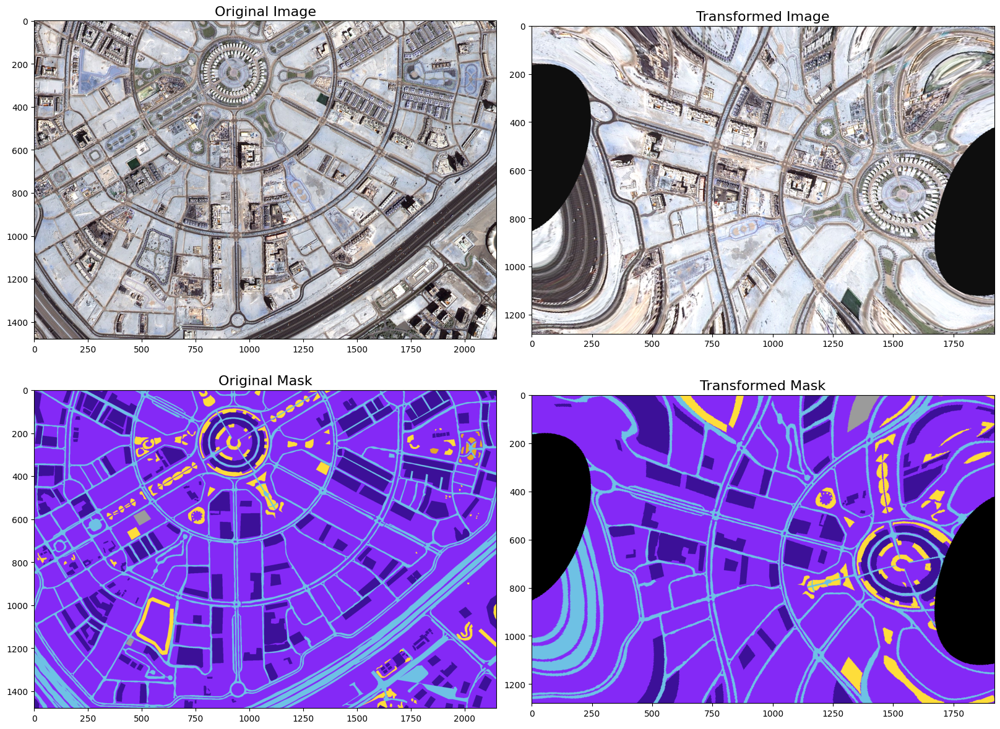

In [6]:
dataset_root = "/content/drive/MyDrive/MBRSC dataset/Semantic segmentation dataset"
image_path = f"{dataset_root}/Tile 8/images/image_part_009.jpg"
mask_path = f"{dataset_root}/Tile 8/masks/image_part_009.png"

image = cv2.imread(image_path)
mask = cv2.imread(mask_path)

# Check that Colab found both files before converting them
if image is None or mask is None:
    raise FileNotFoundError("Could not find the image or mask. Check dataset_root and folder names.")

image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
mask = cv2.cvtColor(mask, cv2.COLOR_BGR2RGB)
transform = augment(1920, 1280) # create an augmentation pipeline with the specified width and height for the random crop operation. The augment function returns a composed transformation that includes random cropping, flipping, rotation, brightness/contrast adjustment, and distortion.
transformed = transform(image=image, mask=mask) # apply the augmentation pipeline to the input image and mask. The transform object is called with the image and mask as keyword arguments, and it returns a dictionary containing the transformed image and mask.
transformed_image = transformed['image']
transformed_mask = transformed['mask']

cv2.imwrite('./image.png',cv2.cvtColor(transformed_image, cv2.COLOR_BGR2RGB)) # save the transformed image to a file named 'image.png' in the current directory. The image is converted from BGR to RGB color space before saving, as OpenCV uses BGR format by default, but most image processing libraries (like matplotlib) use RGB format.
cv2.imwrite('./mask.png',cv2.cvtColor(transformed_mask, cv2.COLOR_BGR2RGB)) # we are again converting BGR to RGB because cv2.imread reads the image in BGR format and we want to save it in RGB format and cv2.imwrite saves the image in BGR format by default, so we need to convert it back to RGB before saving. but we are again doing BGR2RGB because both conversion simply swaps the channels, so it doesn't matter if we do it twice. The final saved image will be in RGB format.

visualize(transformed_image, transformed_mask, image, mask) # call the visualize function to display the original and transformed images and masks. The transformed_image and transformed_mask are passed as the first two arguments, while the original image and mask are passed as the last two arguments. This will create a 2x2 grid of subplots showing the original image, original mask, transformed image, and transformed mask.

# Saving Augmented Images to Disk


In [ ]:
!mkdir aug_images # create a new directory named 'aug_images' in the current working directory to store the augmented images
!mkdir aug_masks # create a new directory named 'aug_masks' in the current working directory to store the augmented masks

In [ ]:
import os
import shutil

dataset_root = "/content/drive/MyDrive/MBRSC dataset/Semantic segmentation dataset"
images_dir = "/content/combined/images"
masks_dir = "/content/combined/masks"

os.makedirs(images_dir, exist_ok=True)
os.makedirs(masks_dir, exist_ok=True)

for tile_number in range(1, 9):
    tile_dir = os.path.join(dataset_root, f"Tile {tile_number}")

    for part in range(1, 10):
        image_name = f"image_part_{part:03d}"
        new_name = f"image_t{tile_number}_{part:03d}"

        shutil.copy2(
            os.path.join(tile_dir, "images", image_name + ".jpg"),
            os.path.join(images_dir, new_name + ".jpg")
        )
        shutil.copy2(
            os.path.join(tile_dir, "masks", image_name + ".png"),
            os.path.join(masks_dir, new_name + ".png")
        )

Updating the dataset to combine all the image and masks into different files rather than being in 8 different tiles

In [ ]:
import shutil # used for high-level file operations like copying and archiving
from google.colab import files

zip_path = shutil.make_archive(
    "/content/combined_dataset", # the name of the output zip file (without the .zip extension)
    "zip", # the format of the archive (zip in this case)
    root_dir="/content",
    base_dir="combined"
)

files.download(zip_path)

In [7]:
dataset_root = "/content/drive/MyDrive/MBRSC dataset/combined_dataset/combined/"
images_dir = f'{dataset_root}/images' # directory containing the original training images
masks_dir = f'{dataset_root}/masks' # directory containing the original training masks

In [8]:
file_names = np.sort(os.listdir(images_dir)) # gets the names of the files in the images_dir and sorts them alphabetically
file_names = np.char.split(file_names, '.') # Splits each filename at the dot, separating its name from its extension.
filenames = np.array([]) # Creates an empty NumPy array to hold the filenames without extensions.
for i in range(len(file_names)):
    filenames = np.append(filenames, file_names[i][0]) # filenames are split at the '.' , so 'file_name' and 'extension' gets appened into the filenames array and we are only fetching the file_names[i][0], 0th posiiton which is only the file name

In [9]:
import cv2
import os

# Load the images using the correct dynamically-defined images_dir variable and print dimensions
img = cv2.imread(os.path.join(images_dir, 'image_t1_001.jpg'))
if img is not None:
    print("img1 shape:", img.shape)
else:
    print(f"Could not load image_t1_001.jpg from {images_dir}")

img2 = cv2.imread(os.path.join(images_dir, 'image_t2_001.jpg'))
if img2 is not None:
    print("img2 shape:", img2.shape)
else:
    print(f"Could not load image_t2_001.jpg from {images_dir}")

img3 = cv2.imread(os.path.join(images_dir, 'image_t3_001.jpg'))
if img3 is not None:
    print("img3 shape:", img3.shape)
else:
    print(f"Could not load image_t3_001.jpg from {images_dir}")

img5 = cv2.imread(os.path.join(images_dir, 'image_t5_001.jpg'))
if img5 is not None:
    print("img5 shape:", img5.shape)
else:
    print(f"Could not load image_t5_001.jpg from {images_dir}")

img6 = cv2.imread(os.path.join(images_dir, 'image_t5_002.jpg'))
if img6 is not None:
    print("img6 shape:", img6.shape)
else:
    print(f"Could not load image_t5_002.jpg from {images_dir}")

img1 shape: (644, 797, 3)
img2 shape: (544, 509, 3)
img3 shape: (658, 682, 3)
img5 shape: (1058, 1126, 3)
img6 shape: (1058, 1126, 3)


As we can see from the above code that each tile of image and mask have a different shape , so we need to apply 8 different types of cropping for the transforation of augmented images

In [ ]:
# Redefining the function with proper path joining using os.path.join()
def augment_dataset_fixed(count):
    '''Function for data augmentation
        Input:
            count - total no. of images after augmentation = initial no. of images * count
        Output:
            writes augmented images (input images & segmentation masks) to the working directory
    '''
    transform_1 = augment(512, 512)
    transform_2 = augment(480, 480)
    transform_3 = augment(512, 512)
    transform_4 = augment(800, 800)
    transform_5 = augment(1024, 1024)
    transform_6 = augment(800, 800)
    transform_7 = augment(1600, 1600)
    transform_8 = augment(1920, 1280)

    # Ensure output directories exist
    os.makedirs('./aug_images', exist_ok=True)
    os.makedirs('./aug_masks', exist_ok=True)

    for i in range(count):
        for file in filenames:
            tile = file.split('_')[1]
            # Fix path concatenation using os.path.join
            img_path = os.path.join(images_dir, file + '.jpg')
            mask_path = os.path.join(masks_dir, file + '.png')

            img = cv2.imread(img_path)
            if img is None:
                print(f"Warning: Could not read image at {img_path}")
                continue
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

            mask = cv2.imread(mask_path)
            if mask is None:
                print(f"Warning: Could not read mask at {mask_path}")
                continue
            mask = cv2.cvtColor(mask, cv2.COLOR_BGR2RGB)

            if tile == 't1':
                transformed = transform_1(image=img, mask=mask)
            elif tile == 't2':
                transformed = transform_2(image=img, mask=mask)
            elif tile == 't3':
                transformed = transform_3(image=img, mask=mask)
            elif tile == 't4':
                transformed = transform_4(image=img, mask=mask)
            elif tile == 't5':
                transformed = transform_5(image=img, mask=mask)
            elif tile == 't6':
                transformed = transform_6(image=img, mask=mask)
            elif tile == 't7':
                transformed = transform_7(image=img, mask=mask)
            elif tile == 't8':
                transformed = transform_8(image=img, mask=mask)
            else:
                continue

            transformed_image = transformed['image']
            transformed_mask = transformed['mask']

            cv2.imwrite('./aug_images/aug_{}_'.format(str(i+1))+file+'.jpg', cv2.cvtColor(transformed_image, cv2.COLOR_RGB2BGR))
            cv2.imwrite('./aug_masks/aug_{}_'.format(str(i+1))+file+'.png', cv2.cvtColor(transformed_mask, cv2.COLOR_RGB2BGR))

# Run the corrected function
augment_dataset_fixed(8)

In [10]:
# find the count of items in the aug_images and aug_masks
import os
aug_images = '/content/drive/MyDrive/MBRSC dataset/aug_images/aug_images'
aug_masks = '/content/drive/MyDrive/MBRSC dataset/aug_masks/aug_masks'

print(f"aug_images count: {len(os.listdir(aug_images))}")
print(f"aug_masks count: {len(os.listdir(aug_masks))}")

aug_images count: 576
aug_masks count: 576


In [ ]:
!zip -r aug_images.zip './aug_images/'
!zip -r aug_masks.zip './aug_masks/'

In [ ]:
!rm -rf './aug_images/' # removes the augmented images directory
!rm -rf './aug_masks/' # removes the augmented masks directory

# Working with Augmented Dataset

The train test split of 80:20.
Maths : we have 72 images and we use 56 images for training and 16 images for validation , the 16 images of validation , we are using the unaugmented images for validation which is 16 original pairs of image-mask.

Now, we have 56* 8 = 448 augmented pairs + 56 original images  = 504 training pairs which contains the original images and masks pairs as well the augmented images and masks pairs(note we are counting pairs not individual image and masks seperately)


The below code does the train test split

In [11]:
dataset_root = "/content/drive/MyDrive/MBRSC dataset/combined_dataset/combined/"
images_dir = f'{dataset_root}/images' # directory containing the original training images
masks_dir = f'{dataset_root}/masks' # directory containing the original training masks

In [ ]:
from pathlib import Path # used for manipulating filesystem paths in a platform-independent way
import shutil # used for high-level file operations like copying and archiving

import cv2
import numpy as np

# These should point to the folders containing the original combined files.
source_images = Path(images_dir)
source_masks = Path(masks_dir)

# Updated output roots to point directly to your unzipped Google Drive datasets
output_images_root = Path("/content/drive/MyDrive/MBRSC dataset/aug_images")
output_masks_root = Path("/content/drive/MyDrive/MBRSC dataset/aug_masks")

# Pair files using their shared filename, such as image_t1_001.
image_paths = {path.stem: path for path in source_images.glob("*.jpg")} # creates a dictionary called image_paths where the keys are the stem (filename without extension) of each .jpg file in the source_images directory, and the values are the corresponding Path objects representing the full paths to those files. This allows for easy access to the image files based on their filenames.
mask_paths = {path.stem: path for path in source_masks.glob("*.png")}

#If names do not match exactly, the code stops with an error:
if image_paths.keys() != mask_paths.keys():
    raise ValueError("Image and mask filenames do not match exactly.")

pair_names = sorted(image_paths) # this code sorts the keys of the image_paths dictionary (which are the filenames without extensions) and stores them in a list called pair_names. This ensures that the image-mask pairs are processed in a consistent order, which is important for maintaining the correct correspondence between images and their respective masks during training and validation.

if len(pair_names) != 72:
    raise ValueError(f"Expected 72 image-mask pairs, found {len(pair_names)}.")

# Split within each tile: 7 training pairs and 2 validation pairs per tile.
rng = np.random.default_rng(42) # Initialize a random number generator with a fixed seed for reproducibility
train_names = []
val_names = []

for tile_number in range(1, 9):
    tile = f"t{tile_number}"
    tile_names = [name for name in pair_names if name.split("_")[1] == tile] # this creates a list called tile_names that contains the filenames of all image-mask pairs corresponding to the current tile (t1, t2, ..., t8). It filters the pair_names list by checking if the second part of each filename (after splitting by underscores) matches the current tile identifier. This ensures that only the relevant pairs for the specific tile are included in tile_names.Example: if tile is 't1', tile_names will contain all filenames that have 't1' as the second part when split by underscores, such as 'image_t1_001', 'image_t1_002', etc.

    if len(tile_names) != 9:
        raise ValueError(f"Expected 9 pairs for {tile}, found {len(tile_names)}.")

    rng.shuffle(tile_names) # Shuffle the list of image-mask pairs for the current tile because we want to randomly select 2 pairs for validation and the rest for training. Shuffling ensures that the selection is random and not biased by the order of the pairs in the original list.
    val_names.extend(tile_names[:2]) # Add the first 2 pairs to the validation set
    train_names.extend(tile_names[2:]) # Add the remaining pairs to the training set

# flow_from_directory expects a subfolder inside each image/mask directory.
train_image_dir = output_images_root / "train_images" / "train" # Directory for training images
train_mask_dir = output_masks_root / "train_masks" / "train" # Directory for training masks
val_image_dir = output_images_root / "val_images" / "val" # Directory for validation images
val_mask_dir = output_masks_root / "val_masks" / "val" # Directory for validation masks

for folder in (train_image_dir, train_mask_dir, val_image_dir, val_mask_dir):
    folder.mkdir(parents=True, exist_ok=True) # This line creates the necessary directories for storing the training and validation images and masks. The `mkdir` method is called on each folder path, with the `parents=True` argument allowing the creation of any missing parent directories, and `exist_ok=True` preventing an error if the directory already exists. This ensures that the required folder structure is in place before saving the images and masks.

# Crop sizes are specified as (width, height), as expected by augment().
crop_sizes = {
    "t1": (512, 512),
    "t2": (480, 480),
    "t3": (512, 512),
    "t4": (800, 800),
    "t5": (1024, 1024),
    "t6": (800, 800),
    "t7": (1600, 1600),
    "t8": (1920, 1280),
}
transforms = {
    tile: augment(width, height)
    for tile, (width, height) in crop_sizes.items()
}

augmentations_per_pair = 8

# Copy each original training pair, then create eight augmented pairs.
for name in train_names:
    image_path = image_paths[name]
    mask_path = mask_paths[name]

    shutil.copy2(image_path, train_image_dir / image_path.name) # Copy the original image to the training directory
    shutil.copy2(mask_path, train_mask_dir / mask_path.name) # Copy the original mask to the training directory

    tile = name.split("_")[1] # this extracts the tile number from the filename, which is in the format 'image_tX_YYY', where X is the tile number and YYY is the image number. The split function splits the filename at the underscore character, and [1] selects the second element of the resulting list, which is the tile number.
    image = cv2.imread(str(image_path))
    mask = cv2.imread(str(mask_path))

    if image is None or mask is None:
        raise OSError(f"Could not read the image or mask for {name}.")

    if image.shape[:2] != mask.shape[:2]:
        raise ValueError(f"Image and mask dimensions do not match for {name}.")

    crop_width, crop_height = crop_sizes[tile]
    if image.shape[1] < crop_width or image.shape[0] < crop_height:
        raise ValueError(
            f"{name} is {image.shape[1]}x{image.shape[0]}, "
            f"which is smaller than the requested crop "
            f"{crop_width}x{crop_height}."
        )

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    mask = cv2.cvtColor(mask, cv2.COLOR_BGR2RGB)

    for index in range(1, augmentations_per_pair + 1):
        result = transforms[tile](image=image, mask=mask)
        augmented_name = f"aug_{index}_{name}"

        cv2.imwrite(
            str(train_image_dir / f"{augmented_name}.jpg"),
            cv2.cvtColor(result["image"], cv2.COLOR_RGB2BGR),
        )
        cv2.imwrite(
            str(train_mask_dir / f"{augmented_name}.png"),
            cv2.cvtColor(result["mask"], cv2.COLOR_RGB2BGR),
        )

# Validation contains only the 16 original pairs; do not augment these.
for name in val_names:
    shutil.copy2(image_paths[name], val_image_dir / image_paths[name].name)
    shutil.copy2(mask_paths[name], val_mask_dir / mask_paths[name].name)

print(f"Training original pairs: {len(train_names)}")
print(f"Training augmented pairs: {len(train_names) * augmentations_per_pair}")
print(
    "Total training pairs, including originals: "
    f"{len(train_names) * (1 + augmentations_per_pair)}"
)
print(f"Validation pairs: {len(val_names)}")
print(f"Output images folder: {output_images_root}")
print(f"Output masks folder: {output_masks_root}")

In [12]:
# Run this once in a new cell to copy data to Colab local SSD:
!cp -r "/content/drive/MyDrive/MBRSC dataset/aug_images" /content/aug_images
!cp -r "/content/drive/MyDrive/MBRSC dataset/aug_masks" /content/aug_masks

# Point paths to local Colab SSD:
train_images = "/content/aug_images/train_images/"
train_masks = "/content/aug_masks/train_masks/"
val_images = "/content/aug_images/val_images/"
val_masks = "/content/aug_masks/val_masks/"

In [13]:
file_names = np.sort(os.listdir(train_images + 'train/'))# This reads all the files currently inside your training images folder (/train_images/train/) and sorts them alphabetically using NumPy's np.sort.
file_names = np.char.split(file_names, '.') # This splits every filename string in the list at the dot (.). For example, 'image_t1_001.jpg' gets split into a list of two elements: ['image_t1_001', 'jpg'].
filenames = np.array([]) # to store clean names (numPy array)
for i in range(len(file_names)):
    filenames = np.append(filenames, file_names[i][0])

# the above loop goes through each split file name [0] index and then appends this base name to the newly created numPy array 'filenames'stripping away the extension

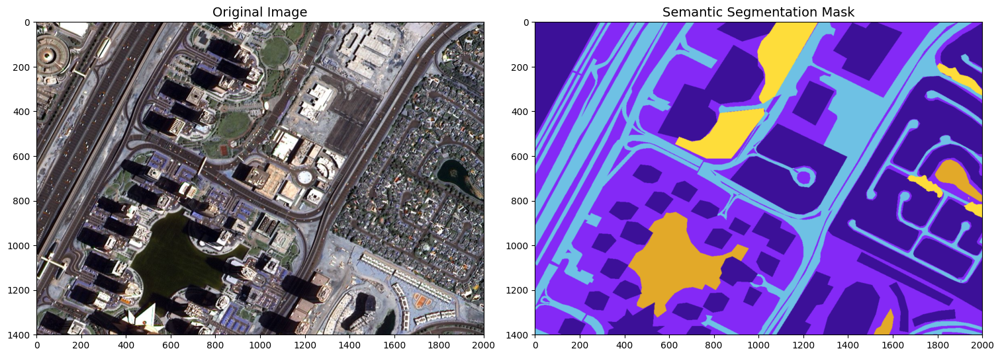

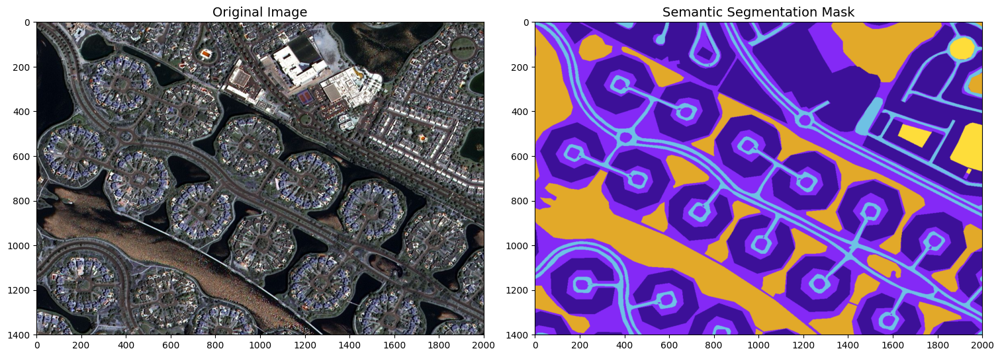

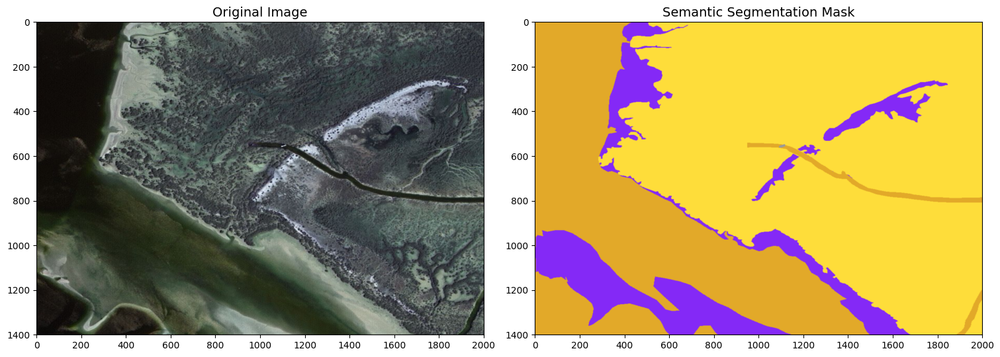

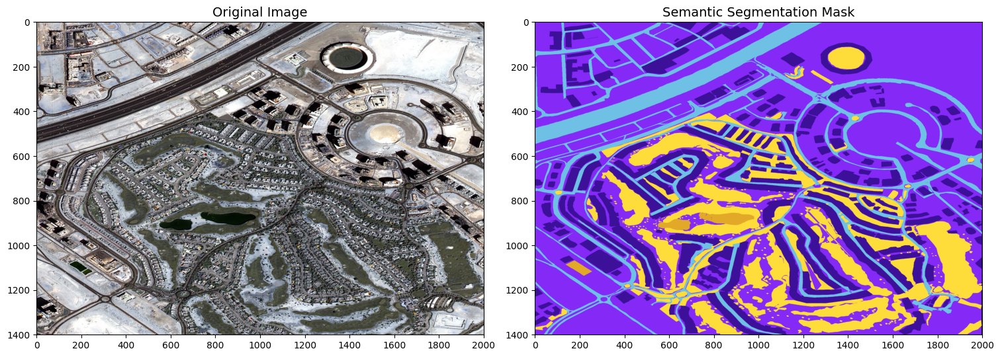

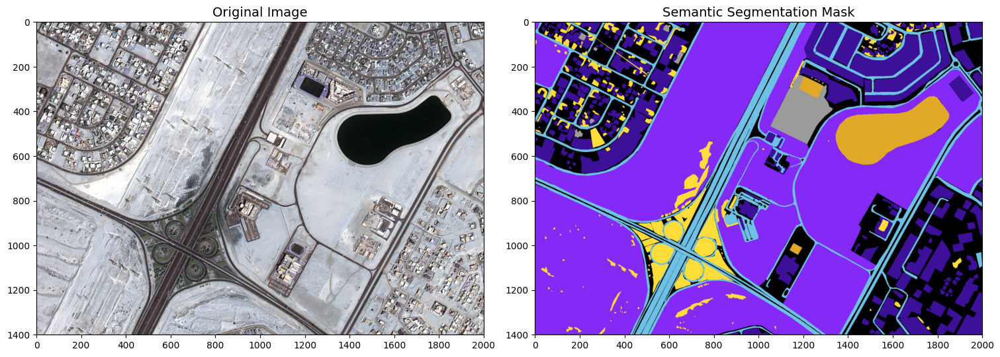

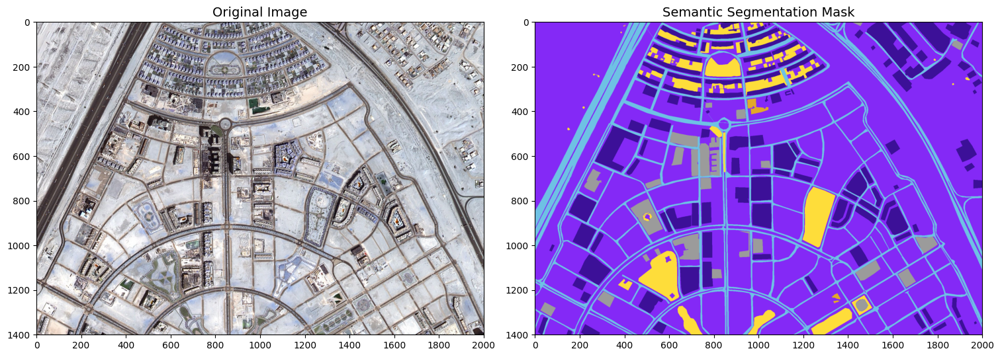

In [14]:
def show_data(files, original_images_dir, label_images_dir):
    for file in files:
        # Check if the file is in the train or validation directory
        """
        Because your dataset was randomized into training and validation sets, any specific filename could be in either directory.
        The code dynamically searches both directories. If the image is found in 'train', it pairs it with the 'train' mask;
        if found in 'val', it pairs it with the 'val' mask.
        If it doesn't exist in either, it prints a warning and moves to the next file."""

        train_img_path = os.path.join(original_images_dir, 'train', f"{file}.jpg")
        val_img_path = os.path.join(original_images_dir, 'val', f"{file}.jpg")

        if os.path.exists(train_img_path):
            img_path = train_img_path
            mask_path = os.path.join(label_images_dir, 'train', f"{file}.png")
        elif os.path.exists(val_img_path):
            img_path = val_img_path
            mask_path = os.path.join(label_images_dir, 'val', f"{file}.png")
        else:
            print(f"Warning: Could not find {file} in train or val folders.")
            continue

        fig, axs = plt.subplots(1, 2, figsize=(15, 6), constrained_layout=True) # 1 row, 2 cols and a figure size of 15 width, 6 inches height and constrained_layout prevents overlapping and dynamic resizing

        # Read and display original image
        img = cv2.imread(img_path) # Expects BGR
        if img is not None:
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
            img = cv2.resize(img, (2000, 1400)) # standardizes all images to a fixed pixel to keep the plotting scale consistent
            axs[0].imshow(img)
        axs[0].set_title('Original Image', fontdict = {'fontsize':14, 'fontweight': 'medium'})
        axs[0].set_xticks(np.arange(0, 2001, 200))
        axs[0].set_yticks(np.arange(0, 1401, 200))
        axs[0].grid(False)
        axs[0].axis(True)

        # Read and display mask
        mask = cv2.imread(mask_path)
        if mask is not None:
            mask = cv2.cvtColor(mask, cv2.COLOR_BGR2RGB)
            mask = cv2.resize(mask, (2000, 1400))
            axs[1].imshow(mask)
        axs[1].set_title('Semantic Segmentation Mask', fontdict = {'fontsize':14, 'fontweight': 'medium'})
        axs[1].set_xticks(np.arange(0, 2001, 200))
        axs[1].set_yticks(np.arange(0, 1401, 200))
        axs[1].grid(False)
        axs[1].axis(True)

        plt.savefig('./sample_'+file, facecolor= 'w', transparent= False, bbox_inches= 'tight', dpi= 100)
        plt.show()

files = ['image_t4_001', 'image_t4_005', 'image_t6_002', 'image_t7_002', 'image_t8_003', 'image_t8_004', 'image_t8_006']
show_data(files, train_images, train_masks)

This block is for visualizing the split and augmentation results. It does not create the train/validation split or generate augmentations; it reads the files that earlier code already saved.

The list candidate_files names five original images the code might display. It then looks inside the training image folder and keeps only candidate names whose original image is present there. For example, if four of the five candidates are in training and one is in validation, augmented_files contains four names. The validation candidate is skipped because this block checks only the training folder; it does not cause an error just because it is in validation.
<br>
For every selected original, show_augmented_images() creates a grid with 3 rows and 6 columns, so each figure has (3 \times 6 = 18) display panels. The first two panels show the original image and its original mask. The other (18 - 2 = 16) panels show the eight augmented images and their eight matching masks: (8 + 8 = 16). Therefore, one figure shows (1 + 8 = 9) image-mask pairs, or (9 times 2 = 18) individual image/mask panels.

The code gets each image and mask from the training folders, converts the colors from OpenCV’s BGR order to RGB for correct display, and resizes them to the dimensions associated with that tile. It labels the panels and saves one comparison figure for each selected original as aug_image_<filename>.png.

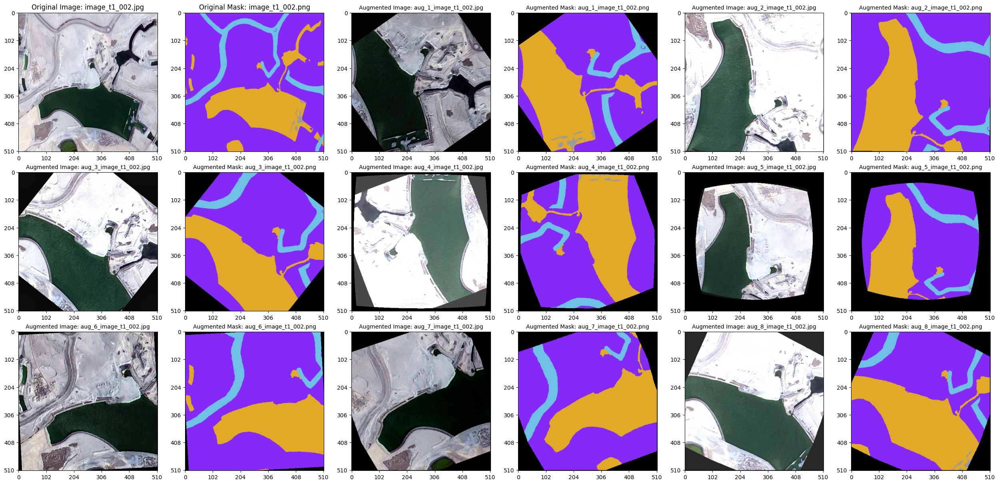

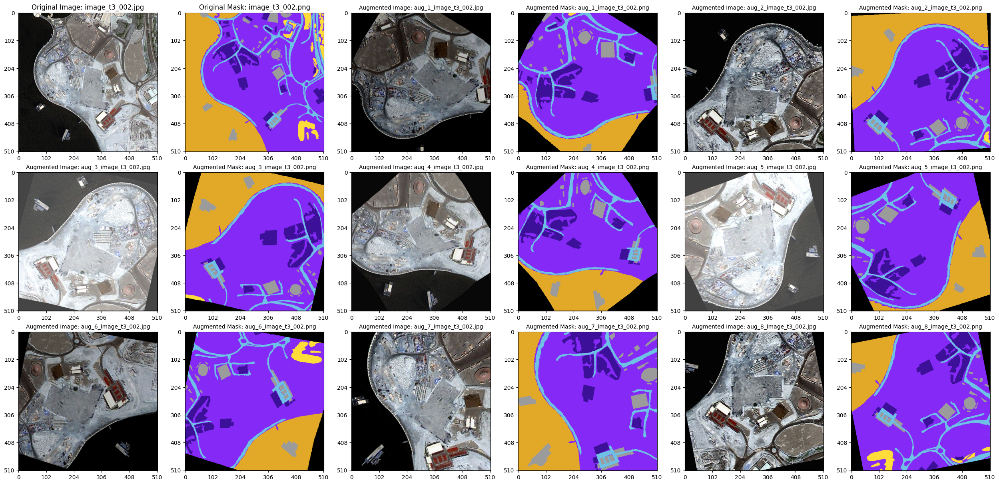

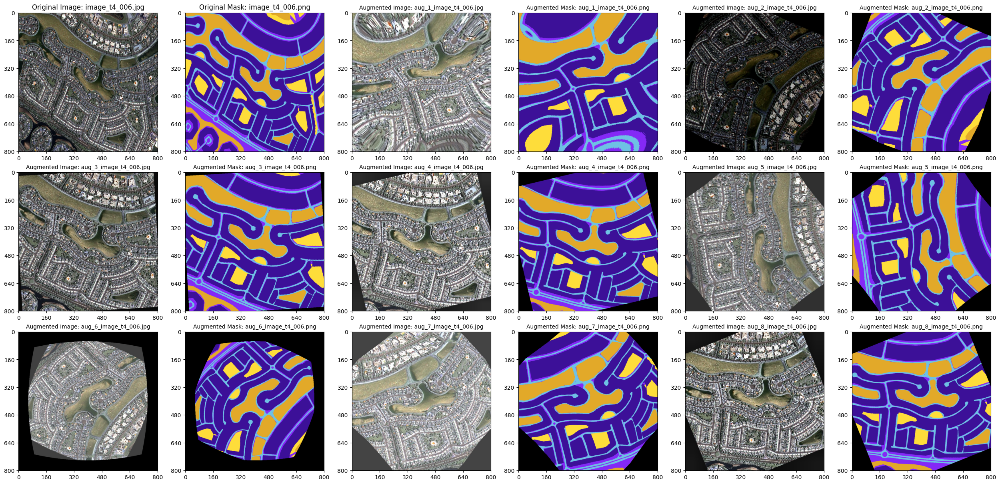

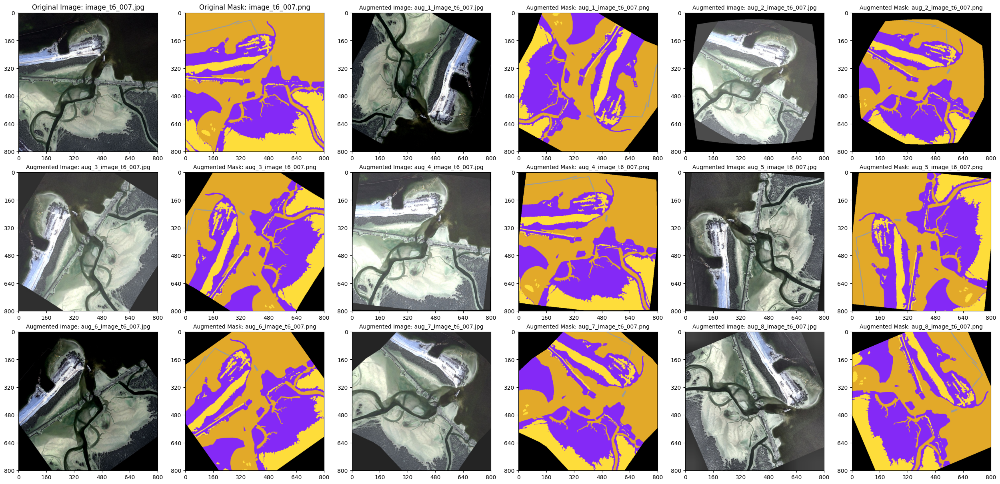

In [15]:
# Helper function to visualize and compare original training images/masks with their 8 augmented counterparts
# This version dynamically finds which requested files are in the training split by scanning the Drive folder, preventing NameErrors.
import os # os is used for interacting with the operating system, such as file and directory operations
import numpy as np
import cv2 # cv2 is the OpenCV library used for computer vision tasks, such as reading and processing images
import matplotlib.pyplot as plt

candidate_files = ['image_t1_002', 'image_t3_002', 'image_t4_006', 'image_t5_004', 'image_t6_007'] # List of candidate files to visualize, which may or may not exist in the training split. These are the base names of the images without extensions. but we have already created a numpy array called 'filenames' which contains the base names of all files in the training split, so we can use that to check for existence instead of hardcoding the list.

# Dynamically check which candidate files exist in the saved training directory on Google Drive
train_dir_path = os.path.join(train_images, 'train') # This constructs the full path to the training images directory by joining the base path of the training images with the 'train' subdirectory. The resulting path points to where the original and augmented training images are stored on Google Drive.
if os.path.exists(train_dir_path): # This checks if the constructed training images directory path actually exists on the filesystem. If it does, the code proceeds to list the files in that directory; if not, it skips the existence check and sets augmented_files to an empty list.
    existing_train_files = {os.path.splitext(f)[0] for f in os.listdir(train_dir_path)}
    augmented_files = [f for f in candidate_files if f in existing_train_files]
else:
    augmented_files = []

# Map each tile prefix to its correct crop dimensions
tile_dims_map = {
    "t1": (512, 512),
    "t2": (480, 480),
    "t3": (512, 512),
    "t4": (800, 800),
    "t5": (1024, 1024),
    "t6": (800, 800),
    "t7": (1600, 1600),
    "t8": (1920, 1280),
}

def show_augmented_images(files, original_images_dir, label_images_dir):
    for file in files:
        tile = file.split('_')[1]
        target_dim = tile_dims_map.get(tile, (512, 512))

        count_img = 1
        count_msk = 1
        fig, axs = plt.subplots(3, 6, figsize=(25, 12), constrained_layout=True)

        for i in range(3):
            for j in range(6):
                if i == 0 and j == 0:
                    orig_img = cv2.imread(os.path.join(original_images_dir, 'train', f"{file}.jpg"))
                    axs[i][j].imshow(cv2.resize(cv2.cvtColor(orig_img, cv2.COLOR_BGR2RGB), target_dim))
                    axs[i][j].set_title(f'Original Image: {file}.jpg', fontsize=12, fontweight='medium')
                    axs[i][j].set_xticks(np.arange(0, target_dim[0]+1, target_dim[0]//5))
                    axs[i][j].set_yticks(np.arange(0, target_dim[1]+1, target_dim[1]//5))
                    axs[i][j].grid(False)
                elif i == 0 and j == 1:
                    orig_msk = cv2.imread(os.path.join(label_images_dir, 'train', f"{file}.png"))
                    axs[i][j].imshow(cv2.resize(cv2.cvtColor(orig_msk, cv2.COLOR_BGR2RGB), target_dim))
                    axs[i][j].set_title(f'Original Mask: {file}.png', fontsize=12, fontweight='medium')
                    axs[i][j].set_xticks(np.arange(0, target_dim[0]+1, target_dim[0]//5))
                    axs[i][j].set_yticks(np.arange(0, target_dim[1]+1, target_dim[1]//5))
                    axs[i][j].grid(False)
                else:
                    if j % 2 == 0:
                        aug_img_path = os.path.join(original_images_dir, 'train', f"aug_{count_img}_{file}.jpg")
                        aug_img = cv2.imread(aug_img_path)
                        axs[i][j].imshow(cv2.resize(cv2.cvtColor(aug_img, cv2.COLOR_BGR2RGB), target_dim))
                        axs[i][j].set_title(f'Augmented Image: aug_{count_img}_{file}.jpg', fontsize=10)
                        axs[i][j].set_xticks(np.arange(0, target_dim[0]+1, target_dim[0]//5))
                        axs[i][j].set_yticks(np.arange(0, target_dim[1]+1, target_dim[1]//5))
                        axs[i][j].grid(False)
                        count_img += 1
                    else:
                        aug_msk_path = os.path.join(label_images_dir, 'train', f"aug_{count_msk}_{file}.png")
                        aug_msk = cv2.imread(aug_msk_path)
                        axs[i][j].imshow(cv2.resize(cv2.cvtColor(aug_msk, cv2.COLOR_BGR2RGB), target_dim))
                        axs[i][j].set_title(f'Augmented Mask: aug_{count_msk}_{file}.png', fontsize=10)
                        axs[i][j].set_xticks(np.arange(0, target_dim[0]+1, target_dim[0]//5))
                        axs[i][j].set_yticks(np.arange(0, target_dim[1]+1, target_dim[1]//5))
                        axs[i][j].grid(False)
                        count_msk += 1

        plt.savefig(f'aug_image_{file}.png', facecolor='w', transparent=False, bbox_inches='tight', dpi=100)
        plt.show()

if len(augmented_files) > 0:
    show_augmented_images(augmented_files, train_images, train_masks)
else:
    print("None of the candidate files were found in the training split directories on your Drive.")

converting the classes.json file to dataframe, to load the colours and classes of the dataset

I have the file donwloaded in local, so No need to run from classes.json because the color coding and semanrtic annotation in classes.json is different

In [ ]:
import json
import pandas as pd

classes_json_path = (
    "/content/drive/MyDrive/MBRSC dataset/"
    "Semantic segmentation dataset/classes.json"
)

with open(classes_json_path, "r") as file:
    class_data = json.load(file)

class_dict_df = pd.DataFrame([
    {
        "name": item["title"],
        "r": int(item["color"][1:3], 16), # This line extracts the red component of the color from the hex string. It takes the substring from index 1 to 3 (skipping the '#' character), converts it from hexadecimal to an integer, and assigns it to the "r" key in the dictionary.
        "g": int(item["color"][3:5], 16),
        "b": int(item["color"][5:7], 16),
    }
    for item in class_data["classes"]
])

class_dict_df


In [ ]:
#download the class_dict_df as a csv file, no need file already in local.
class_dict_df.to_csv("/content/drive/MyDrive/MBRSC dataset/class_dict.csv", index=False)

In [16]:
class_dict_df = pd.read_csv('/content/drive/MyDrive/MBRSC dataset/class_dict.csv', index_col=False, skipinitialspace=True)
class_dict_df

,name,r,g,b
0,building,60,16,152
1,land,132,41,246
2,road,110,193,228
3,vegetation,254,221,58
4,water,226,169,41
5,unlabeled,155,155,155


In [17]:
# this code block extracts the label names and their corresponding RGB color codes from the class_dict_df DataFrame. It creates a list of label names and a list of tuples containing the RGB values for each class. The RGB values are extracted from the DataFrame columns 'r', 'g', and 'b' and converted to tuples. Finally, it returns both the label codes and label names for further use in visualization or processing tasks.

label_names= list(class_dict_df.name)
label_codes = []
r= np.asarray(class_dict_df.r)
g= np.asarray(class_dict_df.g)
b= np.asarray(class_dict_df.b)

for i in range(len(class_dict_df)):
    label_codes.append(tuple([r[i], g[i], b[i]]))

label_codes, label_names

([(np.int64(60), np.int64(16), np.int64(152)),
  (np.int64(132), np.int64(41), np.int64(246)),
  (np.int64(110), np.int64(193), np.int64(228)),
  (np.int64(254), np.int64(221), np.int64(58)),
  (np.int64(226), np.int64(169), np.int64(41)),
  (np.int64(155), np.int64(155), np.int64(155))],
 ['building', 'land', 'road', 'vegetation', 'water', 'unlabeled'])

# Create Useful Label & Code Conversion Dictionaries

These will be used for:

* One hot encoding the mask labels for model training
* Decoding the predicted labels for interpretation and visualization

label_names = ["Water", "Land (unpaved area)", ...]
<br>
label_codes = [(80, 227, 194), (...), ...]

In [18]:
code2id = {v:k for k,v in enumerate(label_codes)} # creates a dictionary called code2id that maps each unique RGB color code (as a tuple) to a unique integer ID. The enumerate function is used to generate the integer IDs, starting from 0, for each color code in the label_codes list. This mapping allows for easy conversion between color codes and their corresponding class IDs, which is useful for tasks like semantic segmentation where each pixel in an image is assigned a class label based on its color. v is the RGB color code (tuple), and k is the corresponding integer ID.

id2code = {k:v for k,v in enumerate(label_codes)} # creates a dictionary called id2code that maps each unique integer ID to its corresponding RGB color code (as a tuple). This is the inverse mapping of code2id.

name2id = {v:k for k,v in enumerate(label_names)} # creates a dictionary called name2id that maps each unique label name to a unique integer ID. The enumerate function is used to generate the integer IDs, starting from 0, for each label name in the label_names list. This mapping allows for easy conversion between label names and their corresponding class IDs.

id2name = {k:v for k,v in enumerate(label_names)} # creates a dictionary called id2name that maps each unique integer ID to its corresponding label name. This is the inverse mapping of name2id.

In [19]:
id2code

{0: (np.int64(60), np.int64(16), np.int64(152)),
 1: (np.int64(132), np.int64(41), np.int64(246)),
 2: (np.int64(110), np.int64(193), np.int64(228)),
 3: (np.int64(254), np.int64(221), np.int64(58)),
 4: (np.int64(226), np.int64(169), np.int64(41)),
 5: (np.int64(155), np.int64(155), np.int64(155))}

In [20]:
id2name

{0: 'building',
 1: 'land',
 2: 'road',
 3: 'vegetation',
 4: 'water',
 5: 'unlabeled'}

# Define Functions for One Hot Encoding RGB Labels & Decoding Encoded Predictions

In [21]:
def rgb_to_onehot(rgb_image, colormap = id2code): # rgb_image is the input RGB image, and colormap is a dictionary that maps class IDs to their corresponding RGB color codes. The default value for colormap is set to id2code, which is a predefined mapping of class IDs to RGB color codes.
    '''Function to one hot encode RGB mask labels
        Inputs:
            rgb_image - image matrix (eg. 256 x 256 x 3 dimension numpy ndarray)
            colormap - dictionary of color to label id
        Output: One hot encoded image of dimensions (height x width x num_classes) where num_classes = len(colormap)
    '''
    num_classes = len(colormap)
    shape = rgb_image.shape[:2]+(num_classes,) # This line creates a new shape for the one-hot encoded image. It takes the height and width of the input RGB image (rgb_image.shape[:2]) and appends the number of classes (num_classes) as the third dimension. The resulting shape will be (height, width, num_classes), which is suitable for storing one-hot encoded representations of each pixel in the image. the rgb_image.shape contains height, width amnd number of colour channels which is 3 for RGB images. [:2} selects only the height and width dimensions, and then (num_classes,) is added to create a new shape for the one-hot encoded image.
    encoded_image = np.zeros( shape, dtype=np.int8 ) # This line initializes an empty NumPy array called encoded_image with the shape defined in the previous line. The array is filled with zeros and has a data type of np.int8, which is an 8-bit signed integer. This array will be used to store the one-hot encoded representation of the input RGB image, where each pixel's class label will be represented as a binary vector across the num_classes dimension.
    for i, cls in enumerate(colormap):
        encoded_image[:,:,i] = np.all(rgb_image.reshape( (-1,3) ) == colormap[i], axis=1).reshape(shape[:2])
    return encoded_image

    #the above loop iterates over each class, where i is the class number and cls is the corresponding RGB color ode from the color map, colormap is id2code whose keys are no. and values are RGB color codes. here reshape ((-1,3)) reshapes the rgb_image into a 2D array where each row represents a pixel and its RGB values. np.all checks if the RGB values of each pixel match the color code for the current class (colormap[i]). The result is a boolean array indicating which pixels belong to the current class. This boolean array is then reshaped back to the original image dimensions (shape[:2]) and assigned to the corresponding channel in the encoded_image array. The final output is a one-hot encoded representation of the input RGB image, where each pixel's class label is represented as a binary vector across the num_classes dimension. axis = 1 means that the comparison is done across the RGB channels for each pixel, and the result is a single boolean value for each pixel indicating whether it matches the class color code.


def onehot_to_rgb(onehot, colormap = id2code): # one hot is one-hot encoded image matrix (height x width x num_classes)
    '''Function to decode encoded mask labels
        Inputs:
            onehot - one hot encoded image matrix (height x width x num_classes)
            colormap - dictionary of color to label id
        Output: Decoded RGB image (height x width x 3)
    '''
    single_layer = np.argmax(onehot, axis=-1)  # For each pixel, argmax finds the class channel with the largest value. For example, [0, 1, 0, 0, 0, 0] becomes class ID 1. axis=-1 means “look across the last dimension,” which here is the class channels.
    output = np.zeros( onehot.shape[:2]+(3,)) # removes the class channel dims which is 6 for each class and adds 3 for RGB channels. This creates an empty output image with the same height and width as the one-hot encoded image, but with 3 channels for RGB color representation.
    # eg. onehot.shape[:2]  # (512, 512): height and width
    # (512, 512) + (3,) # (512, 512, 3): add 3 RGB channels

    #For each class ID k which can be 0, 1, 2, ..., it finds pixels predicted as that class and colors them with the class’s RGB color from colormap.
    for k in colormap.keys():
        output[single_layer==k] = colormap[k]
    return np.uint8(output)

rgb_to_onehot() returns encoded_image with shape (height, width, number_of_classes). With six classes, that is (height, width, 6). The last dimension is class channels, not RGB color channels.

<br>

onehot_to_rgb() converts it back to an RGB image with shape (height, width, 3).
<br>
last line code explanation: <br>

# Creating Custom Image Data Generators
## Defining Data Generators

In [22]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
# Normalizing only frame images, since masks contain label info
data_gen_args = dict(rescale=1./255) # Converts pixel values from 0..255 to 0..1.
mask_gen_args = dict()

train_frames_datagen = ImageDataGenerator(**data_gen_args) # “Create an image generator for training images that rescales pixels from 0–255 to 0–1.”
train_masks_datagen = ImageDataGenerator(**mask_gen_args) # “Create an image generator for training masks that do not require rescaling.”
val_frames_datagen = ImageDataGenerator(**data_gen_args)
val_masks_datagen = ImageDataGenerator(**mask_gen_args)

# Seed defined for aligning images and their masks
seed = 1

# Custom Image Data Generators for Creating Batches of Frames and Masks

The below code performs the following things:
<br>
load one batch of training/validation images
load matching batch of masks
convert each mask from RGB color mask to one-hot form
return:
- image batch
- one-hot mask batch
<br>
So the model receives:

- input: image tensor, shape like (batch, 512, 512, 3)
- target: one-hot mask tensor, shape like (batch, 512, 512, 6)

In [ ]:
def TrainAugmentGenerator(train_images_dir, train_masks_dir, seed=1, batch_size=8, target_size=(512, 512)): # batch size 8 is the default fallback but we are using 4 as passed arguments in model.fit
    '''Train Image data generator'''
    train_image_generator = train_frames_datagen.flow_from_directory(
        train_images_dir,
        batch_size=batch_size, # here batch_size=4 is explicitly passed!
        seed=seed,
        target_size=target_size
    )

    train_mask_generator = train_masks_datagen.flow_from_directory(
        train_masks_dir,
        batch_size=batch_size,
        seed=seed,
        target_size=target_size
    )

    while True:
        # Use next(iterator) instead of iterator.next()
        X1i = next(train_image_generator)
        X2i = next(train_mask_generator)

        # One hot encoding RGB masks
        mask_encoded = [rgb_to_onehot(X2i[0][x, :, :, :], id2code) for x in range(X2i[0].shape[0])]

        yield X1i[0], np.asarray(mask_encoded, dtype=np.float32)


def ValAugmentGenerator(val_images_dir, val_masks_dir, seed=1, batch_size=8, target_size=(512, 512)):
    '''Validation Image data generator'''
    val_image_generator = val_frames_datagen.flow_from_directory(
        val_images_dir,
        batch_size=batch_size,
        seed=seed,
        target_size=target_size
    )

    val_mask_generator = val_masks_datagen.flow_from_directory(
        val_masks_dir,
        batch_size=batch_size,
        seed=seed,
        target_size=target_size
    )

    while True:
        # Use next(iterator) instead of iterator.next()
        X1i = next(val_image_generator)
        X2i = next(val_mask_generator)

        # One hot encoding RGB masks
        mask_encoded = [rgb_to_onehot(X2i[0][x, :, :, :], id2code) for x in range(X2i[0].shape[0])]

        yield X1i[0], np.asarray(mask_encoded, dtype=np.float32)

so, in short the above code created batches of images and their class-label masks in one hot encoded (6) (height,width,6) format that the model can be trained on and later the model output can be converted back to coloured masks for viewing, we are only converting the masks into one hot because eg. class 2  -> [0, 0, 1, 0, 0, 0] is water, so it contains the class labels for training and we are not converting the raw frames/images because The model needs the image as normal pixel values to understand the scene.

# Model

### Calculating Training & Validation Steps

To ensure the model trains on the entire dataset in each epoch without running out of GPU memory, we set **`batch_size = 4`** for our $512 \times 512$ high-resolution tiles.

#### 1. Training Steps per Epoch:
* **Total augmented training images:** `504` (56 original pairs × 9 augmented variants)
* **Batch size:** `4`
$$\text{steps\_per\_epoch} = \left\lceil \frac{504}{4} \right\rceil = \mathbf{126\text{ steps}}$$
*The model performs 126 weight update steps per epoch to see all 504 images.*

#### 2. Validation Steps:
* **Unique validation images:** `16` (unaugmented)
$$\text{validation\_steps} = \left\lceil \frac{4 \times 16}{4} \right\rceil = \mathbf{16\text{ steps}}$$
*Keras evaluates 16 validation batches of size 4 per epoch.*

- Your neural network does not wait until all 504 images are processed to learn. Instead, it processes 4 images at a time, calculates the error, and adjusts (updates) its weights. This happens 126 times per epoch.
-Gradient Quality vs. Speed: A batch size of 4 means your gradients are estimated from a small sample of images. This makes each individual step fast and memory-efficient, though the loss curve may oscillate or bounce around more compared to larger batches.
-  At step 126, the model has seen all 504 images exactly once, completing one full epoch

In [30]:
batch_size = 4

num_train_samples = len(np.sort(os.listdir(train_images + 'train')))
num_val_samples = len(np.sort(os.listdir(val_images + 'val')))

# Use int() around np.ceil
steps_per_epoch = int(np.ceil(float(num_train_samples) / float(batch_size)))
validation_steps = int(np.ceil(float(4 * num_val_samples) / float(batch_size)))

print('steps_per_epoch: ', steps_per_epoch, type(steps_per_epoch))
print('validation_steps: ', validation_steps, type(validation_steps))

steps_per_epoch:  126 <class 'int'>
validation_steps:  16 <class 'int'>


steps per epoch means :
This means:

one training epoch = one full pass through all training data
if each batch contains 16 images, then we need this many batches to finish one epoch
Example:

if train images = 504
then steps_per_epoch = ceil(504 / 16) = 32
So the model will do 32 training steps in one epoch.

## InceptionResNetV2 UNet

The below code block inputs a staellite image, outputs a segmentation map where each pixel is assigned to eone of the classes out of 6 classes.

<br>

### What is happening here
This model is a U-Net segmentation model whose encoder is a pretrained `InceptionResNetV2`.

So:

- `U-Net` = the segmentation structure
- `InceptionResNetV2` = the feature extractor / encoder
- the decoder reconstructs the mask at full resolution

This is a standard and very reasonable design for satellite/aerial segmentation.

---

### Why the backbone helps
You are right that the pretrained backbone gives useful low-, mid-, and high-level feature maps.

That helps because:
- early layers capture edges, textures, boundaries
- middle layers capture object shapes and patterns
- deep layers capture semantic meaning

For aerial imagery, those features matter a lot.

---

### Why InceptionResNetV2 is useful here
Your explanation is also correct on the two key properties:

1. Multi-scale feature extraction
   - Inception blocks use multiple kernel sizes in parallel
   - this helps capture small details and larger spatial patterns together
   - very useful for satellite scenes where roads, buildings, water, and vegetation have different scales

2. Residual learning / skip connections
   - InceptionResNetV2 includes residual-style connections
   - this helps with gradient flow
   - it makes deep networks train more stably
   - this reduces the vanishing gradient problem

So yes, your understanding of “dynamic kernel size + parallel processing + residual flow” is accurate.

---

### Why U-Net is needed on the decoder side
This is also correct.

The decoder:
- upsamples feature maps
- concatenates them with earlier encoder features via skip connections
- reconstructs the image at high resolution
- outputs pixel-wise class predictions

This is exactly why U-Net works well for segmentation:
- it preserves spatial details
- it combines both deep semantic context and fine boundary information

---

### One small correction
It is slightly more precise to say:

- InceptionResNetV2 is pretrained on ImageNet, not “already trained to do satellite images”
- but it is trained on general visual patterns, and those features transfer well to satellite imagery

So the model is not magically “trained for satellite segmentation,” but it is a strong visual feature extractor that works well as a starting point.

---

### Your summary
Your explanation is essentially correct:

- pretrained encoder for feature extraction
- U-Net decoder for upsampling and mask reconstruction
- InceptionResNetV2 captures multi-scale details
- residual connections help with training stability
- U-Net restores spatial structure for segmentation output



In [25]:
def conv_block(input, num_filters): # This function defines a convolutional block that consists of two convolutional layers, each followed by batch normalization and a ReLU activation function. The purpose of this block is to extract features from the input tensor while maintaining the spatial dimensions through padding. input is the image tensor that will be processed by the convolutional layers, and num_filters specifies the number of filters (or feature maps) to be used in each convolutional layer. The function returns the output tensor after applying the convolutional operations, which can then be used in building more complex neural network architectures, such as U-Net or other encoder-decoder models.
    x = Conv2D(num_filters, 3, padding="same")(input) # 3 is kernel size which denotes the spatial extent of the convolutional filter, same means that the output feature map will have the same spatial dimensions as the input feature map, achieved by adding appropriate padding to the input before applying the convolution. This ensures that the spatial resolution of the feature maps is preserved throughout the network, which is important for tasks like image segmentation where precise localization is required. num_filters means the number of filters (or feature maps) to be used in the convolutional layer of kernal size 3. Each filter will learn to detect different features in the input image, such as edges, textures, or patterns. The more filters you have, the more complex features the network can learn to recognize.
    x = BatchNormalization()(x) # Batch normalization helps to stabilize the training process by normalizing the inputs to each layer, which can lead to faster convergence and better performance.
    x = Activation("relu")(x) # turns -ve to 0, Rectified Linear Unit (ReLU)

    x = Conv2D(num_filters, 3, padding="same")(x) # This line applies a second convolutional layer to the output of the previous layer (x).
    x = BatchNormalization()(x)
    x = Activation("relu")(x)

    return x
#the decoder part of the U-Net
def decoder_block(input, skip_features, num_filters): # input is low res feature map from the previous layer, skip_features is the corresponding high-resolution feature map from the encoder that will be concatenated with the upsampled input, and num_filters specifies the number of filters to be used in the convolutional layers of this decoder block. The purpose of this function is to upsample the low-resolution feature map, concatenate it with the high-resolution features from the encoder, and then apply convolutional operations to refine the combined features. This process helps to recover spatial information lost during downsampling in the encoder and allows for more accurate predictions in tasks like image segmentation.
    x = Conv2DTranspose(num_filters, (2, 2), strides=2, padding="same")(input) # upsamples the feature map by 2x
    x = Concatenate()([x, skip_features]) # concatenates the upsampled feature map with the corresponding high-resolution feature map from the encoder
    x = conv_block(x, num_filters) # applies the conv_block function to the concatenated feature maps, which consists of two convolutional layers, each followed by batch normalization and a ReLU activation function. This helps to refine the combined features and extract relevant information for the segmentation task.
    return x

def build_inception_resnetv2_unet(input_shape):
    """ Input """
    inputs = Input(input_shape)

    """ Pre-trained InceptionResNetV2 Model """
    encoder = InceptionResNetV2(include_top=False, weights="imagenet", input_tensor=inputs)

    """ Encoder """
    # s1 is simply the input image tensor (512 x 512 x 3)
    s1 = inputs

    s2 = encoder.get_layer("activation").output        ## (255 x 255)
    s2 = ZeroPadding2D(( (1, 0), (1, 0) ))(s2)         ## (256 x 256)

    s3 = encoder.get_layer("activation_3").output      ## (126 x 126)
    s3 = ZeroPadding2D((1, 1))(s3)                     ## (128 x 128)

    s4 = encoder.get_layer("activation_74").output      ## (61 x 61)
    s4 = ZeroPadding2D(( (2, 1),(2, 1) ))(s4)           ## (64 x 64)

    """ Bridge """
    b1 = encoder.get_layer("activation_161").output     ## (30 x 30)
    b1 = ZeroPadding2D((1, 1))(b1)                      ## (32 x 32)

    """ Decoder """
    d1 = decoder_block(b1, s4, 512)                     ## (64 x 64)
    d2 = decoder_block(d1, s3, 256)                     ## (128 x 128)
    d3 = decoder_block(d2, s2, 128)                     ## (256 x 256)
    d4 = decoder_block(d3, s1, 64)                      ## (512 x 512)

    """ Output """
    dropout = Dropout(0.3)(d4)
    outputs = Conv2D(6, 1, padding="same", activation="softmax")(dropout)

    model = Model(inputs, outputs, name="InceptionResNetV2-UNet")
    return model

In [26]:
K.clear_session()

def dice_coef(y_true, y_pred):
    return (2. * K.sum(y_true * y_pred) + 1.) / (K.sum(y_true) + K.sum(y_pred) + 1.)

model = build_inception_resnetv2_unet(input_shape = (512, 512, 3))
model.compile(optimizer=Adam(learning_rate=0.0001), loss='categorical_crossentropy', metrics=[dice_coef, "accuracy"])
model.summary()

219055592/219055592 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "InceptionResNetV2-UNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 512, 512,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 255, 255,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalization │ (None, 255, 255,  │         96 │ conv2d[0][0]      │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 255, 255,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 253, 253,  │      9,216 │ activation[0][0]  │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 253, 253,  │         96 │ conv2d_1[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_1        │ (None, 253, 253,  │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 253, 253,  │     18,432 │ activation_1[0][… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 253, 253,  │        192 │ conv2d_2[0][0]    │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_2        │ (None, 253, 253,  │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 126, 126,  │          0 │ activation_2[0][… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 126, 126,  │      5,120 │ max_pooling2d[0]… │
│                     │ 80)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 126, 126,  │        240 │ conv2d_3[0][0]    │
│ (BatchNormalizatio… │ 80)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_3        │ (None, 126, 126,  │          0 │ batch_normalizat… │
│ (Activation)        │ 80)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 124, 124,  │    138,240 │ activation_3[0][… │
│                     │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 124, 124,  │        576 │ conv2d_4[0][0]    │
│ (BatchNormalizatio… │ 192)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_4        │ (None, 124, 124,  │          0 │ batch_normalizat

 Total params: 36,793,414 (140.36 MB)

 Trainable params: 36,752,390 (140.20 MB)

 Non-trainable params: 41,024 (160.25 KB)

In [27]:
from IPython.display import Image, display
import os

image_path = '/content/drive/MyDrive/MBRSC dataset/model_architecture_diagram_final.png'

if os.path.exists(image_path):
    display(Image(image_path))
else:
    print(f"Error: The file {image_path} does not exist.")

In [28]:
# this code block defines a learning rate scheduler function called exponential_decay, which adjusts the learning rate during training based on the current epoch. The function takes two parameters: lr0 (the initial learning rate) and s (the decay step). It returns a nested function exponential_decay_fn that calculates the learning rate for a given epoch using the formula lr0 * 0.1 **(epoch / s). This means that the learning rate will decrease exponentially as the number of epochs increases, allowing for finer adjustments to the model's weights as training progresses. The exponential_decay_fn is then used in a LearningRateScheduler callback to dynamically update the learning rate during training.


def exponential_decay(lr0, s):
    def exponential_decay_fn(epoch):
        return lr0 * 0.1 **(epoch / s)
    return exponential_decay_fn

exponential_decay_fn = exponential_decay(0.0001, 60)

lr_scheduler = LearningRateScheduler( # the lr_scheduler is a callback that adjusts the learning rate during training based on the exponential decay function defined above. It takes the exponential_decay_fn as an argument, which calculates the learning rate for each epoch according to the specified decay schedule. The verbose parameter is set to 1, which means that the learning rate changes will be printed to the console during training, allowing for monitoring of how the learning rate evolves over time.
    exponential_decay_fn,
    verbose=1
)

# this code block defines three callbacks for the training process: ModelCheckpoint, EarlyStopping, and CSVLogger. These callbacks help manage the training process by saving the best model, stopping training early if the validation loss does not improve, and logging training metrics to a CSV file.
checkpoint = ModelCheckpoint(
    filepath = 'InceptionResNetV2-UNet.h5',
    save_best_only = True,
#     save_weights_only = False,
    monitor = 'val_loss',
    mode = 'auto',
    verbose = 1
)

earlystop = EarlyStopping(
    monitor = 'val_loss',
    min_delta = 0.001,
    patience = 12,
    mode = 'auto',
    verbose = 1,
    restore_best_weights = True
)

csvlogger = CSVLogger(
    filename= "model_training.csv",
    separator = ",",
    append = False
)

callbacks = [checkpoint, earlystop, csvlogger, lr_scheduler]

In [31]:
history = model.fit(
    TrainAugmentGenerator(
        train_images_dir=train_images,
        train_masks_dir=train_masks,
        batch_size=batch_size,
        target_size=(512, 512)
    ),
    steps_per_epoch=steps_per_epoch,
    validation_data=ValAugmentGenerator(
        val_images_dir=val_images,
        val_masks_dir=val_masks,
        batch_size=batch_size,
        target_size=(512, 512)
    ),
    validation_steps=validation_steps,
    epochs=50,
    callbacks=callbacks,
    verbose=1
)

Found 504 images belonging to 1 classes.
Found 504 images belonging to 1 classes.

Epoch 1: LearningRateScheduler setting learning rate to 0.0001.
Epoch 1/50
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.4918 - dice_coef: 0.3573 - loss: 1.1112Found 16 images belonging to 1 classes.
Found 16 images belonging to 1 classes.

Epoch 1: val_loss improved from None to 0.97684, saving model to InceptionResNetV2-UNet.h5



Epoch 1: finished saving model to InceptionResNetV2-UNet.h5
126/126 ━━━━━━━━━━━━━━━━━━━━ 425s 1s/step - accuracy: 0.5794 - dice_coef: 0.4357 - loss: 0.9351 - val_accuracy: 0.7660 - val_dice_coef: 0.4333 - val_loss: 0.9768 - learning_rate: 1.0000e-04

Epoch 2: LearningRateScheduler setting learning rate to 9.623506263980886e-05.
Epoch 2/50
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.6830 - dice_coef: 0.5460 - loss: 0.6844
Epoch 2: val_loss improved from 0.97684 to 0.61529, saving model to InceptionResNetV2-UNet.h5



Epoch 2: finished saving model to InceptionResNetV2-UNet.h5
126/126 ━━━━━━━━━━━━━━━━━━━━ 176s 1s/step - accuracy: 0.6903 - dice_coef: 0.5593 - loss: 0.6682 - val_accuracy: 0.8230 - val_dice_coef: 0.6549 - val_loss: 0.6153 - learning_rate: 9.6235e-05

Epoch 3: LearningRateScheduler setting learning rate to 9.261187281287936e-05.
Epoch 3/50
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7188 - dice_coef: 0.6023 - loss: 0.5850
Epoch 3: val_loss improved from 0.61529 to 0.52587, saving model to InceptionResNetV2-UNet.h5



Epoch 3: finished saving model to InceptionResNetV2-UNet.h5
126/126 ━━━━━━━━━━━━━━━━━━━━ 174s 1s/step - accuracy: 0.7293 - dice_coef: 0.6161 - loss: 0.5575 - val_accuracy: 0.8338 - val_dice_coef: 0.7220 - val_loss: 0.5259 - learning_rate: 9.2612e-05

Epoch 4: LearningRateScheduler setting learning rate to 8.912509381337456e-05.
Epoch 4/50
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7461 - dice_coef: 0.6412 - loss: 0.4951
Epoch 4: val_loss improved from 0.52587 to 0.48899, saving model to InceptionResNetV2-UNet.h5



Epoch 4: finished saving model to InceptionResNetV2-UNet.h5
126/126 ━━━━━━━━━━━━━━━━━━━━ 175s 1s/step - accuracy: 0.7552 - dice_coef: 0.6499 - loss: 0.4821 - val_accuracy: 0.8445 - val_dice_coef: 0.7442 - val_loss: 0.4890 - learning_rate: 8.9125e-05

Epoch 5: LearningRateScheduler setting learning rate to 8.576958985908941e-05.
Epoch 5/50
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7755 - dice_coef: 0.6680 - loss: 0.4475
Epoch 5: val_loss improved from 0.48899 to 0.48880, saving model to InceptionResNetV2-UNet.h5



Epoch 5: finished saving model to InceptionResNetV2-UNet.h5
126/126 ━━━━━━━━━━━━━━━━━━━━ 174s 1s/step - accuracy: 0.7723 - dice_coef: 0.6696 - loss: 0.4432 - val_accuracy: 0.8414 - val_dice_coef: 0.7432 - val_loss: 0.4888 - learning_rate: 8.5770e-05

Epoch 6: LearningRateScheduler setting learning rate to 8.254041852680184e-05.
Epoch 6/50
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7877 - dice_coef: 0.6915 - loss: 0.4040
Epoch 6: val_loss improved from 0.48880 to 0.46884, saving model to InceptionResNetV2-UNet.h5



Epoch 6: finished saving model to InceptionResNetV2-UNet.h5
126/126 ━━━━━━━━━━━━━━━━━━━━ 175s 1s/step - accuracy: 0.7830 - dice_coef: 0.6891 - loss: 0.4054 - val_accuracy: 0.8495 - val_dice_coef: 0.7708 - val_loss: 0.4688 - learning_rate: 8.2540e-05

Epoch 7: LearningRateScheduler setting learning rate to 7.943282347242815e-05.
Epoch 7/50
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.7959 - dice_coef: 0.7036 - loss: 0.3885
Epoch 7: val_loss improved from 0.46884 to 0.46761, saving model to InceptionResNetV2-UNet.h5



Epoch 7: finished saving model to InceptionResNetV2-UNet.h5
126/126 ━━━━━━━━━━━━━━━━━━━━ 175s 1s/step - accuracy: 0.7914 - dice_coef: 0.7033 - loss: 0.3761 - val_accuracy: 0.8488 - val_dice_coef: 0.7726 - val_loss: 0.4676 - learning_rate: 7.9433e-05

Epoch 8: LearningRateScheduler setting learning rate to 7.644222742526003e-05.
Epoch 8/50
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8025 - dice_coef: 0.7179 - loss: 0.3448
Epoch 8: val_loss improved from 0.46761 to 0.45612, saving model to InceptionResNetV2-UNet.h5



Epoch 8: finished saving model to InceptionResNetV2-UNet.h5
126/126 ━━━━━━━━━━━━━━━━━━━━ 172s 1s/step - accuracy: 0.8024 - dice_coef: 0.7201 - loss: 0.3437 - val_accuracy: 0.8552 - val_dice_coef: 0.7658 - val_loss: 0.4561 - learning_rate: 7.6442e-05

Epoch 9: LearningRateScheduler setting learning rate to 7.356422544596415e-05.
Epoch 9/50
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8083 - dice_coef: 0.7277 - loss: 0.3301
Epoch 9: val_loss improved from 0.45612 to 0.45062, saving model to InceptionResNetV2-UNet.h5



Epoch 9: finished saving model to InceptionResNetV2-UNet.h5
126/126 ━━━━━━━━━━━━━━━━━━━━ 203s 2s/step - accuracy: 0.8078 - dice_coef: 0.7280 - loss: 0.3263 - val_accuracy: 0.8571 - val_dice_coef: 0.7795 - val_loss: 0.4506 - learning_rate: 7.3564e-05

Epoch 10: LearningRateScheduler setting learning rate to 7.07945784384138e-05.
Epoch 10/50
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8105 - dice_coef: 0.7298 - loss: 0.3252
Epoch 10: val_loss improved from 0.45062 to 0.44202, saving model to InceptionResNetV2-UNet.h5



Epoch 10: finished saving model to InceptionResNetV2-UNet.h5
126/126 ━━━━━━━━━━━━━━━━━━━━ 177s 1s/step - accuracy: 0.8126 - dice_coef: 0.7342 - loss: 0.3140 - val_accuracy: 0.8581 - val_dice_coef: 0.7807 - val_loss: 0.4420 - learning_rate: 7.0795e-05

Epoch 11: LearningRateScheduler setting learning rate to 6.812920690579614e-05.
Epoch 11/50
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8139 - dice_coef: 0.7393 - loss: 0.2999
Epoch 11: val_loss improved from 0.44202 to 0.43859, saving model to InceptionResNetV2-UNet.h5



Epoch 11: finished saving model to InceptionResNetV2-UNet.h5
126/126 ━━━━━━━━━━━━━━━━━━━━ 175s 1s/step - accuracy: 0.8164 - dice_coef: 0.7423 - loss: 0.3009 - val_accuracy: 0.8565 - val_dice_coef: 0.7888 - val_loss: 0.4386 - learning_rate: 6.8129e-05

Epoch 12: LearningRateScheduler setting learning rate to 6.556418494179789e-05.
Epoch 12/50
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8228 - dice_coef: 0.7469 - loss: 0.2980
Epoch 12: val_loss did not improve from 0.43859
126/126 ━━━━━━━━━━━━━━━━━━━━ 168s 1s/step - accuracy: 0.8170 - dice_coef: 0.7412 - loss: 0.3015 - val_accuracy: 0.8534 - val_dice_coef: 0.7809 - val_loss: 0.4555 - learning_rate: 6.5564e-05

Epoch 13: LearningRateScheduler setting learning rate to 6.309573444801933e-05.
Epoch 13/50
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8260 - dice_coef: 0.7525 - loss: 0.2903
Epoch 13: val_loss improved from 0.43859 to 0.43831, saving model to InceptionResNetV2-UNet.h5



Epoch 13: finished saving model to InceptionResNetV2-UNet.h5
126/126 ━━━━━━━━━━━━━━━━━━━━ 173s 1s/step - accuracy: 0.8192 - dice_coef: 0.7483 - loss: 0.2895 - val_accuracy: 0.8580 - val_dice_coef: 0.7878 - val_loss: 0.4383 - learning_rate: 6.3096e-05

Epoch 14: LearningRateScheduler setting learning rate to 6.072021956909886e-05.
Epoch 14/50
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8241 - dice_coef: 0.7528 - loss: 0.2855
Epoch 14: val_loss did not improve from 0.43831
126/126 ━━━━━━━━━━━━━━━━━━━━ 168s 1s/step - accuracy: 0.8198 - dice_coef: 0.7507 - loss: 0.2871 - val_accuracy: 0.8547 - val_dice_coef: 0.7908 - val_loss: 0.4477 - learning_rate: 6.0720e-05

Epoch 15: LearningRateScheduler setting learning rate to 5.8434141337351765e-05.
Epoch 15/50
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8286 - dice_coef: 0.7609 - loss: 0.2669
Epoch 15: val_loss improved from 0.43831 to 0.43806, saving model to InceptionResNetV2-UNet.h5



Epoch 15: finished saving model to InceptionResNetV2-UNet.h5
126/126 ━━━━━━━━━━━━━━━━━━━━ 171s 1s/step - accuracy: 0.8270 - dice_coef: 0.7605 - loss: 0.2647 - val_accuracy: 0.8587 - val_dice_coef: 0.7909 - val_loss: 0.4381 - learning_rate: 5.8434e-05

Epoch 16: LearningRateScheduler setting learning rate to 5.623413251903491e-05.
Epoch 16/50
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8266 - dice_coef: 0.7585 - loss: 0.2663
Epoch 16: val_loss did not improve from 0.43806
126/126 ━━━━━━━━━━━━━━━━━━━━ 168s 1s/step - accuracy: 0.8295 - dice_coef: 0.7634 - loss: 0.2598 - val_accuracy: 0.8569 - val_dice_coef: 0.7869 - val_loss: 0.4511 - learning_rate: 5.6234e-05

Epoch 17: LearningRateScheduler setting learning rate to 5.4116952654646367e-05.
Epoch 17/50
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8374 - dice_coef: 0.7736 - loss: 0.2469
Epoch 17: val_loss did not improve from 0.43806
126/126 ━━━━━━━━━━━━━━━━━━━━ 168s 1s/step - accuracy: 0.8335 - dice_coef: 0.7715 - loss


Epoch 21: finished saving model to InceptionResNetV2-UNet.h5
126/126 ━━━━━━━━━━━━━━━━━━━━ 175s 1s/step - accuracy: 0.8369 - dice_coef: 0.7801 - loss: 0.2298 - val_accuracy: 0.8633 - val_dice_coef: 0.8110 - val_loss: 0.4367 - learning_rate: 4.6416e-05

Epoch 22: LearningRateScheduler setting learning rate to 4.4668359215096314e-05.
Epoch 22/50
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8404 - dice_coef: 0.7848 - loss: 0.2280
Epoch 22: val_loss did not improve from 0.43671
126/126 ━━━━━━━━━━━━━━━━━━━━ 168s 1s/step - accuracy: 0.8383 - dice_coef: 0.7834 - loss: 0.2245 - val_accuracy: 0.8646 - val_dice_coef: 0.8105 - val_loss: 0.4405 - learning_rate: 4.4668e-05

Epoch 23: LearningRateScheduler setting learning rate to 4.298662347082277e-05.
Epoch 23/50
126/126 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.8375 - dice_coef: 0.7790 - loss: 0.2333
Epoch 23: val_loss did not improve from 0.43671
126/126 ━━━━━━━━━━━━━━━━━━━━ 167s 1s/step - accuracy: 0.8390 - dice_coef: 0.7822 - loss

In [32]:
df_result = pd.DataFrame(history.history) # This line creates a Pandas DataFrame called df_result from the history.history attribute of the model training process. The history.history attribute is a dictionary that contains the recorded values of the loss and metrics for each epoch during training and validation. By converting this dictionary into a DataFrame, it allows for easier analysis, visualization, and manipulation of the training results, such as plotting learning curves or saving the results to a file for further examination.
df_result

,accuracy,dice_coef,loss,val_accuracy,val_dice_coef,val_loss,learning_rate
0,0.579364,0.435691,0.935111,0.765982,0.433259,0.976843,0.000100
1,0.690347,0.559345,0.668225,0.822965,0.654887,0.615291,0.000096
2,0.729319,0.616090,0.557468,0.833800,0.721988,0.525866,0.000093
3,0.755193,0.649927,0.482087,0.844492,0.744186,0.488989,0.000089
4,0.772269,0.669570,0.443229,0.841430,0.743243,0.488798,0.000086
5,0.782955,0.689098,0.405410,0.849536,0.770805,0.468837,0.000083
6,0.791375,0.703266,0.376132,0.848753,0.772616,0.467612,0.000079
7,0.802357,0.720065,0.343737,0.855170,0.765796,0.456125,0.000076
8,0.807759,0.728015,0.326344,0.857135,0.779540,0.450618,0.000074
9,0.812568,0.734199,0.313950,0.858083,0.780656,0.442019,0.000071


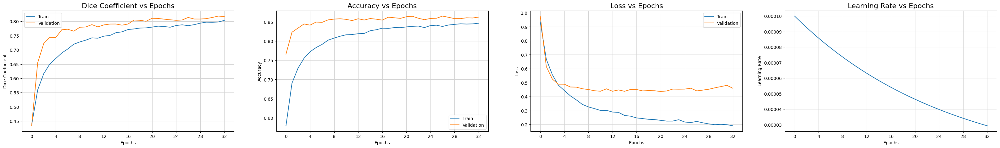

In [34]:
fig, ax = plt.subplots(1, 4, figsize=(40, 5))
ax = ax.ravel()
metrics = ['Dice Coefficient', 'Accuracy', 'Loss', 'Learning Rate']

# Use 'learning_rate' instead of 'lr'
lr_key = 'learning_rate' if 'learning_rate' in history.history else 'lr'
num_epochs = len(history.history['loss'])

for i, met in enumerate(['dice_coef', 'accuracy', 'loss', lr_key]):
    if met != lr_key:
        ax[i].plot(history.history[met])
        ax[i].plot(history.history['val_' + met])
        ax[i].set_title('{} vs Epochs'.format(metrics[i]), fontsize=16)
        ax[i].set_xlabel('Epochs')
        ax[i].set_ylabel(metrics[i])
        ax[i].set_xticks(np.arange(0, num_epochs + 1, 4))
        ax[i].legend(['Train', 'Validation'])
        ax[i].xaxis.grid(True, color = "lightgray", linewidth = "0.8", linestyle = "-")
        ax[i].yaxis.grid(True, color = "lightgray", linewidth = "0.8", linestyle = "-")
    else:
        ax[i].plot(history.history[met])
        ax[i].set_title('{} vs Epochs'.format(metrics[i]), fontsize=16)
        ax[i].set_xlabel('Epochs')
        ax[i].set_ylabel(metrics[i])
        ax[i].set_xticks(np.arange(0, num_epochs + 1, 4))
        ax[i].xaxis.grid(True, color = "lightgray", linewidth = "0.8", linestyle = "-")
        ax[i].yaxis.grid(True, color = "lightgray", linewidth = "0.8", linestyle = "-")

plt.savefig('model_metrics_plot.png', facecolor='w', transparent=False, bbox_inches='tight', dpi=150)
plt.show()

In [36]:
# 1. Modern Keras format (.keras)
model.save("InceptionResNetV2-UNet.keras")

# 2. Legacy HDF5 full model (.h5)
model.save("InceptionResNetV2-UNet.h5")

# 3. Weights-only (must end in .weights.h5 in Keras 3)
model.save_weights("InceptionResNetV2-UNet.weights.h5")

print("All formats saved successfully!")

All formats saved successfully!


In [37]:
# Copy all 3 formats to your Google Drive root folder:
!cp "InceptionResNetV2-UNet.keras" "/content/drive/MyDrive/"
!cp "InceptionResNetV2-UNet.h5" "/content/drive/MyDrive/"
!cp "InceptionResNetV2-UNet.weights.h5" "/content/drive/MyDrive/"

print("Copied to Google Drive successfully!")

Copied to Google Drive successfully!


In [38]:
model.load_weights("./InceptionResNetV2-UNet.weights.h5") # This line loads the weights of the trained model from the specified file path "./InceptionResNetV2-UNet.h5". By loading these weights, the model is restored to its state after training, allowing for further evaluation, predictions, or fine-tuning without needing to retrain the model from scratch. This is particularly useful for deploying the model or continuing training with additional data.

In [39]:
# Create a validation data generator for augmented validation data, this generator will yield batches of validation images and their corresponding one-hot encoded masks for evaluation or further training. The generator is created using the ValAugmentGenerator function, which takes the validation images directory (val_images), validation masks directory (val_masks), and the target size for resizing the images and masks (512, 512) as input parameters. The resulting testing_gen can be used to iterate over the validation dataset in a structured manner, ensuring that the images and masks are properly aligned and preprocessed for model evaluation.
testing_gen = ValAugmentGenerator(val_images_dir = val_images, val_masks_dir = val_masks, target_size = (512, 512))

In [40]:
!mkdir predictions

Found 16 images belonging to 1 classes.
Found 16 images belonging to 1 classes.
1/1 ━━━━━━━━━━━━━━━━━━━━ 63s 63s/step


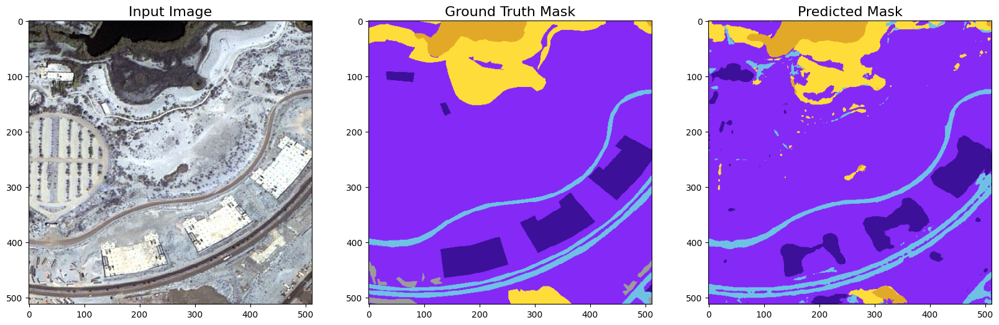

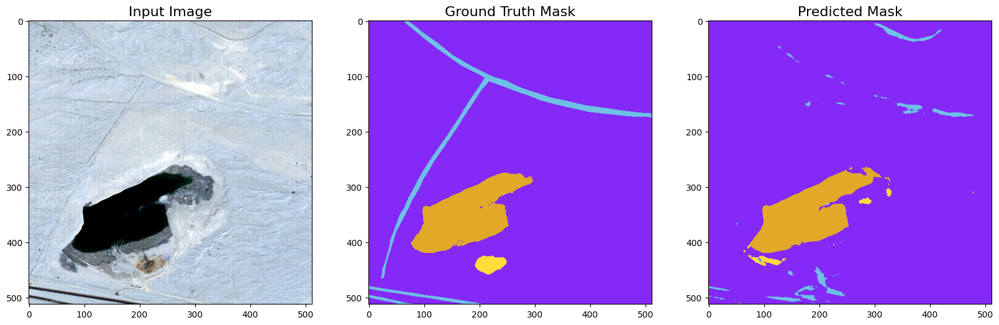

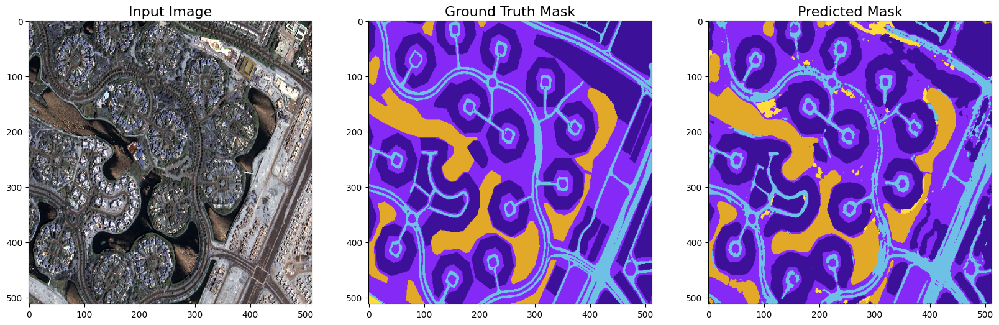

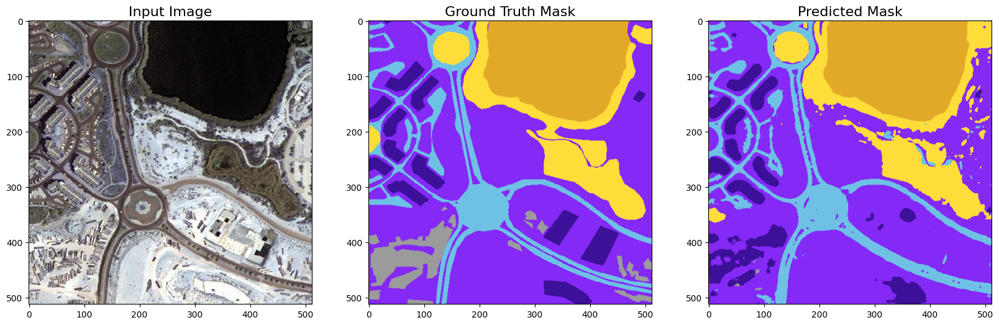

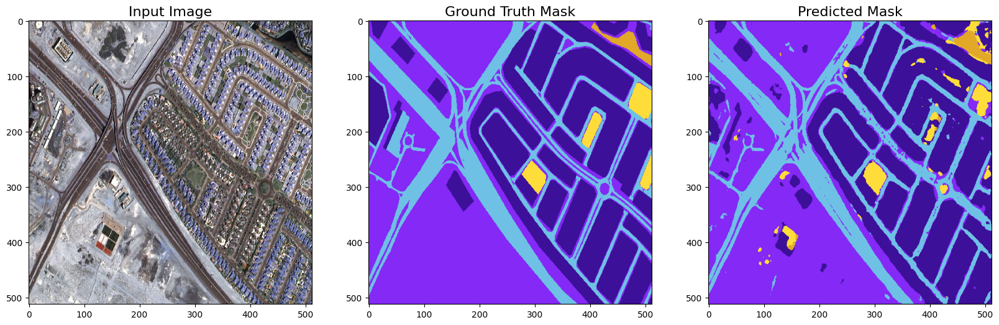

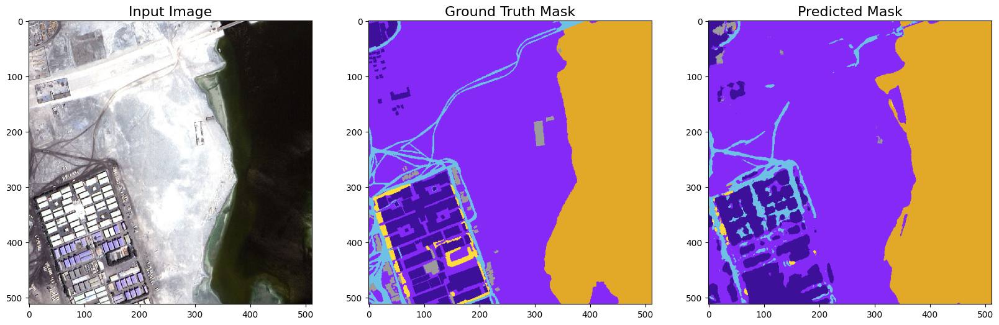

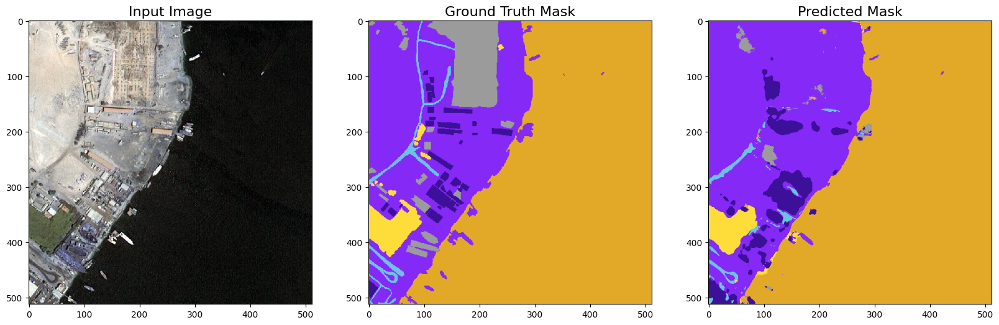

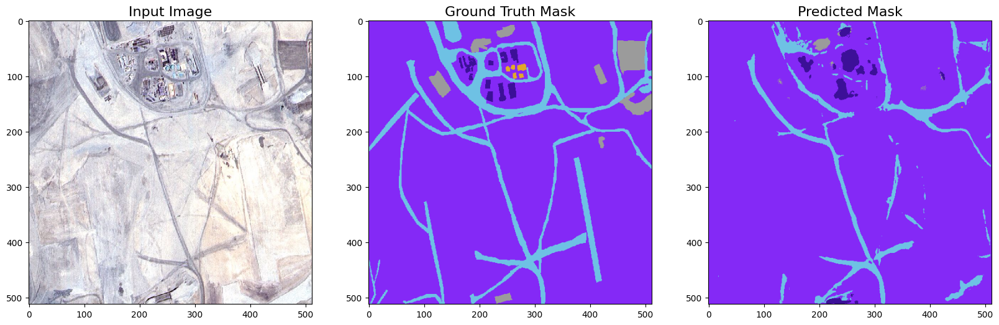

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 865ms/step


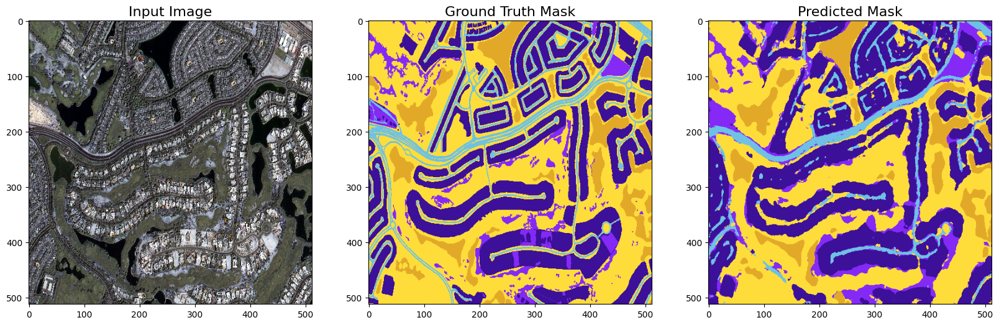

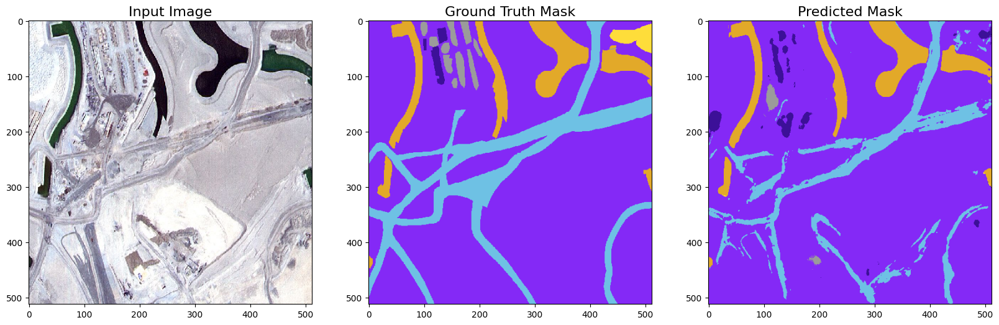

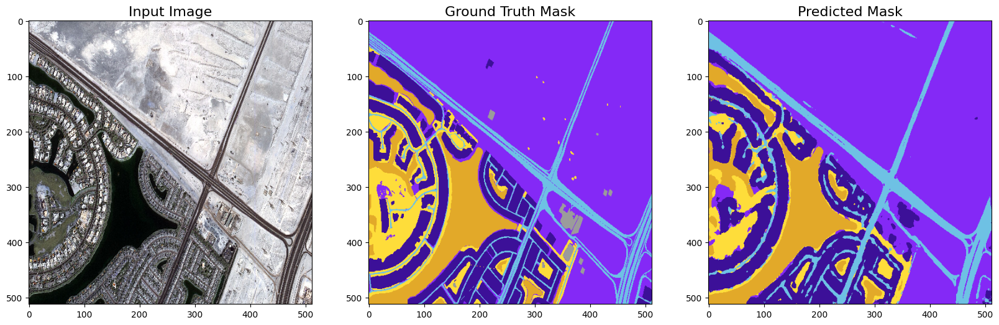

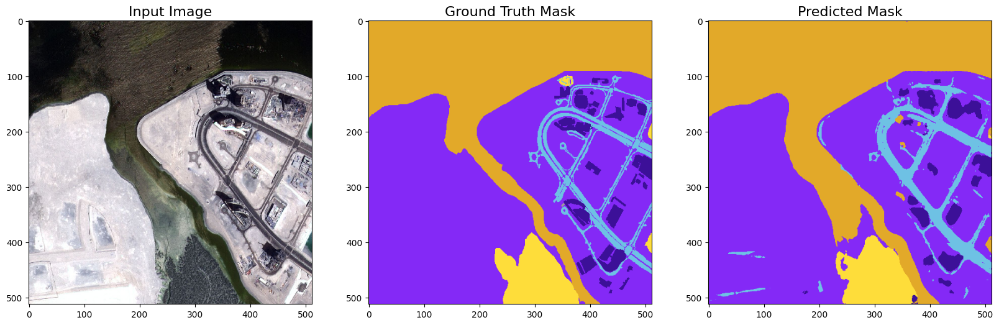

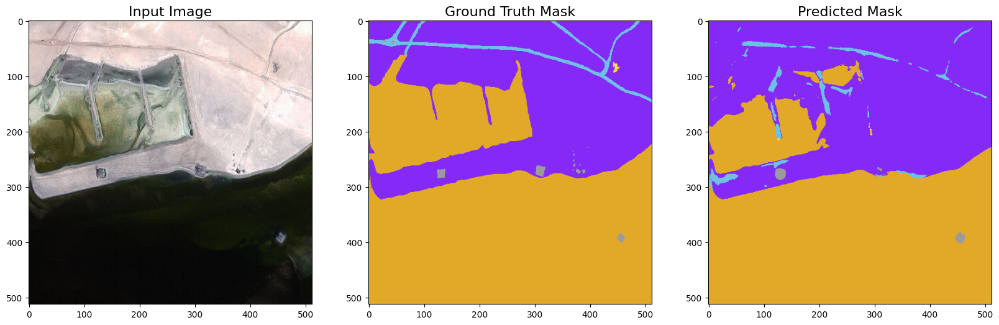

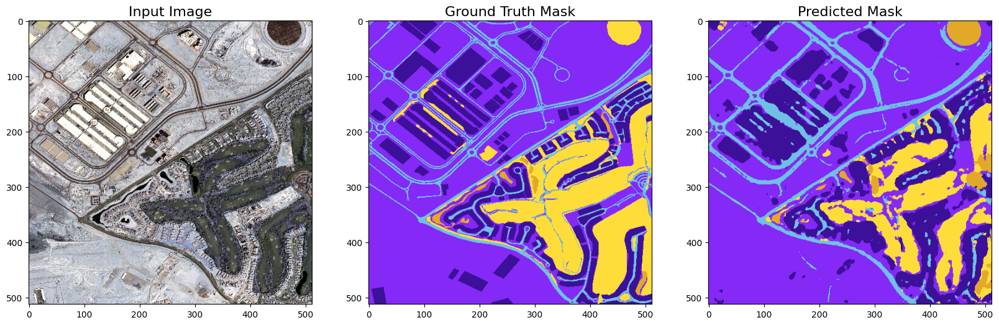

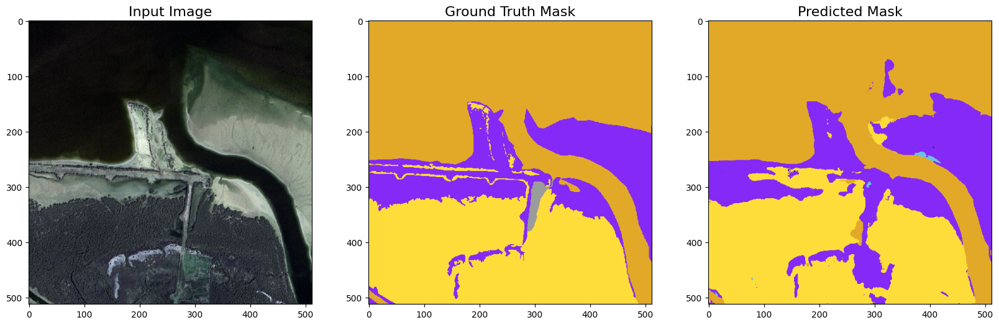

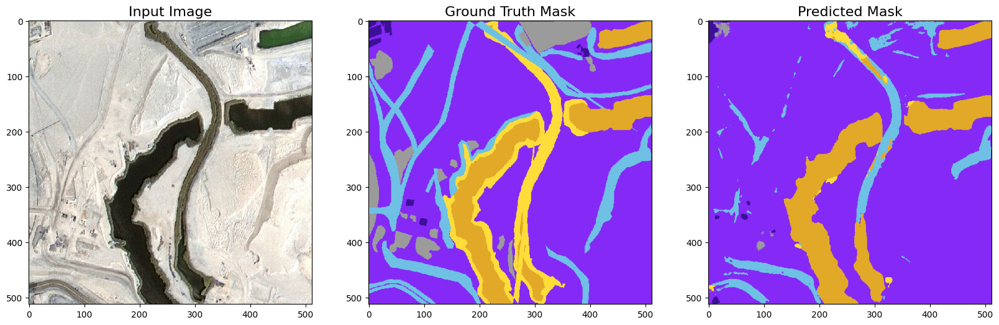

In [41]:
# the below code block generates predictions for a specified number of batches from the validation dataset using the trained model. It iterates through the batches, retrieves the input images and their corresponding ground truth masks, and then uses the model to predict the segmentation masks for the input images. For each image in the batch, it creates a figure with three subplots: one for the input image, one for the ground truth mask, and one for the predicted mask. The predicted masks are converted from one-hot encoded format back to RGB format using the onehot_to_rgb function. Each figure is saved as a PNG file in the "predictions" directory with a unique filename based on the count of processed images. Finally, the figures are displayed using plt.show().

count = 0
for i in range(2):
    batch_img,batch_mask = next(testing_gen)
    pred_all= model.predict(batch_img)
    np.shape(pred_all)

    for j in range(0,np.shape(pred_all)[0]):
        count += 1
        fig = plt.figure(figsize=(20,8))

        ax1 = fig.add_subplot(1,3,1)
        ax1.imshow(batch_img[j])
        ax1.set_title('Input Image', fontdict={'fontsize': 16, 'fontweight': 'medium'})
        ax1.grid(False)

        ax2 = fig.add_subplot(1,3,2)
        ax2.set_title('Ground Truth Mask', fontdict={'fontsize': 16, 'fontweight': 'medium'})
        ax2.imshow(onehot_to_rgb(batch_mask[j],id2code))
        ax2.grid(False)

        ax3 = fig.add_subplot(1,3,3)
        ax3.set_title('Predicted Mask', fontdict={'fontsize': 16, 'fontweight': 'medium'})
        ax3.imshow(onehot_to_rgb(pred_all[j],id2code))
        ax3.grid(False)

        plt.savefig('./predictions/prediction_{}.png'.format(count), facecolor= 'w', transparent= False, bbox_inches= 'tight', dpi= 200)
        plt.show()

In [42]:
!zip -r predictions.zip "./predictions"

  adding: predictions/ (stored 0%)
  adding: predictions/prediction_5.png (deflated 0%)
  adding: predictions/prediction_15.png (deflated 2%)
  adding: predictions/prediction_6.png (deflated 1%)
  adding: predictions/prediction_8.png (deflated 1%)
  adding: predictions/prediction_2.png (deflated 2%)
  adding: predictions/prediction_4.png (deflated 1%)
  adding: predictions/prediction_12.png (deflated 1%)
  adding: predictions/prediction_7.png (deflated 1%)
  adding: predictions/prediction_3.png (deflated 0%)
  adding: predictions/prediction_1.png (deflated 1%)
  adding: predictions/prediction_14.png (deflated 0%)
  adding: predictions/prediction_10.png (deflated 1%)
  adding: predictions/prediction_13.png (deflated 2%)
  adding: predictions/prediction_16.png (deflated 1%)
  adding: predictions/prediction_9.png (deflated 0%)
  adding: predictions/prediction_11.png (deflated 0%)


In [ ]:
!rm -rf './predictions/'

Evaluating Validation Set across all classes...
Found 16 images belonging to 1 classes.
Found 16 images belonging to 1 classes.

=== BASELINE MODEL METRICS SUMMARY ===


,Class,IoU,Dice / F1,Precision,Recall
0,building,0.6806,0.8099,0.7799,0.8423
1,land,0.8083,0.8940,0.8733,0.9157
2,road,0.5105,0.6759,0.6999,0.6535
3,vegetation,0.6163,0.7626,0.8441,0.6954
4,water,0.9015,0.9482,0.9429,0.9536
5,unlabeled,0.0282,0.0548,0.3341,0.0298
6,Mean (mIoU / Overall),0.5909,0.6909,0.7457,0.6817


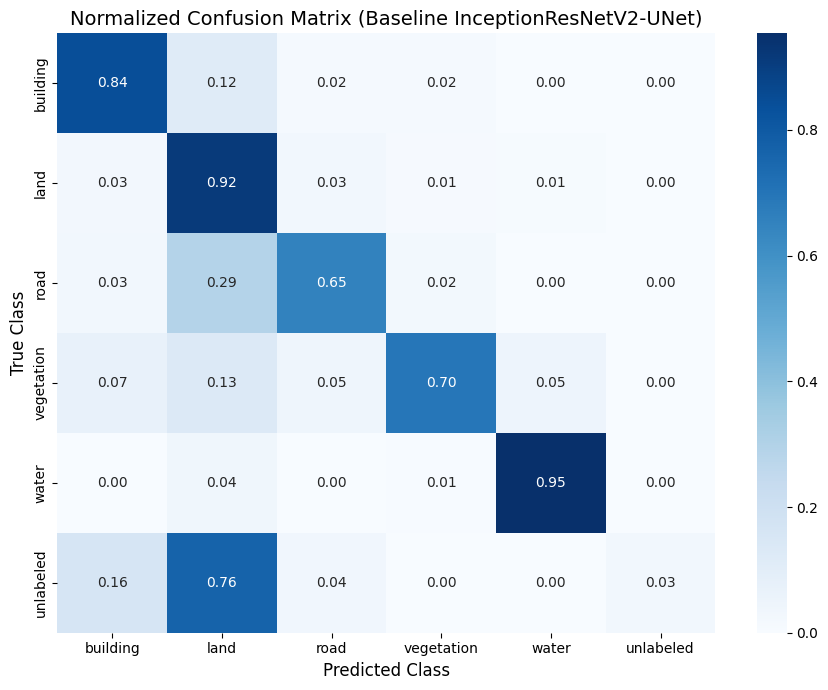

In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

print("Evaluating Validation Set across all classes...")

# 1. Collect ground truth and predictions for all validation images
val_gen = ValAugmentGenerator(val_images_dir=val_images, val_masks_dir=val_masks, batch_size=4, target_size=(512, 512))
num_val_images = len(os.listdir(val_images + 'val'))
val_steps = int(np.ceil(num_val_images / 4))

all_true = []
all_pred = []

for step in range(val_steps):
    imgs, masks = next(val_gen)
    preds = model.predict(imgs, verbose=0)

    # Convert one-hot to class index (0 to 5)
    true_classes = np.argmax(masks, axis=-1).flatten()
    pred_classes = np.argmax(preds, axis=-1).flatten()

    all_true.extend(true_classes)
    all_pred.extend(pred_classes)

all_true = np.array(all_true)
all_pred = np.array(all_pred)

# 2. Confusion Matrix
classes = label_names  # ['building', 'land', 'road', 'vegetation', 'water', 'unlabeled']
cm = confusion_matrix(all_true, all_pred, labels=range(len(classes)))

# 3. Calculate Per-Class IoU, Precision, Recall, F1/Dice
intersection = np.diag(cm)
ground_truth_set = cm.sum(axis=1)
predicted_set = cm.sum(axis=0)
union = ground_truth_set + predicted_set - intersection

iou = intersection / np.maximum(union, 1e-7)
precision = intersection / np.maximum(predicted_set, 1e-7)
recall = intersection / np.maximum(ground_truth_set, 1e-7)
f1_dice = (2 * intersection) / np.maximum(ground_truth_set + predicted_set, 1e-7)

# 4. Create Metrics Table
metrics_df = pd.DataFrame({
    'Class': classes,
    'IoU': np.round(iou, 4),
    'Dice / F1': np.round(f1_dice, 4),
    'Precision': np.round(precision, 4),
    'Recall': np.round(recall, 4)
})

# Overall Summary Row
overall_row = pd.DataFrame([{
    'Class': 'Mean (mIoU / Overall)',
    'IoU': np.round(np.mean(iou), 4),
    'Dice / F1': np.round(np.mean(f1_dice), 4),
    'Precision': np.round(np.mean(precision), 4),
    'Recall': np.round(np.mean(recall), 4)
}])
metrics_df = pd.concat([metrics_df, overall_row], ignore_index=True)
metrics_df.to_csv("baseline_metrics_table.csv", index=False)

print("\n=== BASELINE MODEL METRICS SUMMARY ===")
display(metrics_df)

# 5. Plot Normalized Confusion Matrix
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
plt.figure(figsize=(9, 7))
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=classes, yticklabels=classes, cbar=True)
plt.title("Normalized Confusion Matrix (Baseline InceptionResNetV2-UNet)", fontsize=14)
plt.xlabel("Predicted Class", fontsize=12)
plt.ylabel("True Class", fontsize=12)
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=200)
plt.show()

Found 16 images belonging to 1 classes.
Found 16 images belonging to 1 classes.


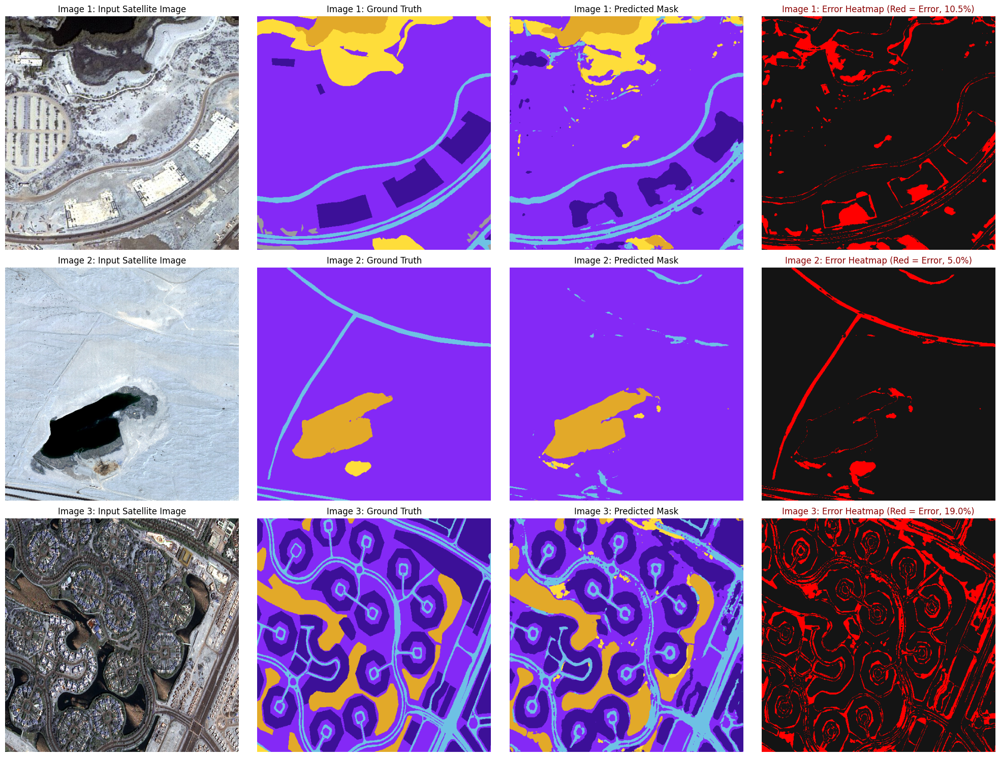

In [45]:
# Block 2 (Fixed): Visual Error Heatmaps with Vivid Bright RED Misclassifications
sample_gen = ValAugmentGenerator(val_images_dir=val_images, val_masks_dir=val_masks, batch_size=3, target_size=(512, 512))
batch_imgs, batch_masks = next(sample_gen)
batch_preds = model.predict(batch_imgs, verbose=0)

fig, axes = plt.subplots(3, 4, figsize=(20, 15))

for i in range(3):
    img = batch_imgs[i]
    gt_rgb = onehot_to_rgb(batch_masks[i], id2code)
    pred_rgb = onehot_to_rgb(batch_preds[i], id2code)

    # Extract class indices
    gt_cls = np.argmax(batch_masks[i], axis=-1)
    pred_cls = np.argmax(batch_preds[i], axis=-1)

    # Boolean mask: True where model made a mistake
    error_mask = (gt_cls != pred_cls)
    error_percent = (error_mask.sum() / error_mask.size) * 100

    # Create explicit RGB image for error heatmap
    error_rgb = np.zeros((512, 512, 3), dtype=np.uint8)
    error_rgb[~error_mask] = [20, 20, 20]     # Correct pixels = Dark background
    error_rgb[error_mask] = [255, 0, 0]       # Misclassified pixels = Bright Vivid RED

    # 1. Input Image
    axes[i, 0].imshow(img)
    axes[i, 0].set_title(f"Image {i+1}: Input Satellite Image", fontsize=12)
    axes[i, 0].axis('off')

    # 2. Ground Truth Mask
    axes[i, 1].imshow(gt_rgb)
    axes[i, 1].set_title(f"Image {i+1}: Ground Truth", fontsize=12)
    axes[i, 1].axis('off')

    # 3. Model Predicted Mask
    axes[i, 2].imshow(pred_rgb)
    axes[i, 2].set_title(f"Image {i+1}: Predicted Mask", fontsize=12)
    axes[i, 2].axis('off')

    # 4. Vivid Red Error Map
    axes[i, 3].imshow(error_rgb)
    axes[i, 3].set_title(f"Image {i+1}: Error Heatmap (Red = Error, {error_percent:.1f}%)", fontsize=12, color='darkred')
    axes[i, 3].axis('off')

plt.tight_layout()
plt.savefig("prediction_error_heatmaps.png", dpi=200, bbox_inches='tight')
plt.show()

"Because the physical embedded drone hardware was unavailable, we used a CPU proxy environment: we constrained execution strictly to /CPU:0 with a batch size of 1 to replicate real-time, single-frame onboard capture.
After 5 warmup iterations to eliminate cache initialization bias, we measured steady-state latency over 15 runs using high-resolution performance counters. This established our baseline edge latency of 4.69 seconds per image (0.21 FPS)."

In [47]:
# Block 3 (Fixed): Edge / On-Device Deployment Metrics Benchmark
import time
import os
import numpy as np
import pandas as pd
import tensorflow as tf

print("Benchmarking Model Parameters & Inference Speeds...")

# 1. Parameter Counts & Disk Size
total_params = model.count_params()
trainable_params = sum([tf.size(w).numpy() for w in model.trainable_weights])
model_size_mb = os.path.getsize("InceptionResNetV2-UNet.keras") / (1024 * 1024)

# 2. Benchmark GPU Latency (with warmup)
dummy_tensor = tf.random.normal([1, 512, 512, 3], dtype=tf.float32)

for _ in range(10):  # GPU Warmup
    _ = model(dummy_tensor, training=False)

gpu_times = []
for _ in range(30):
    start = time.perf_counter()
    _ = model(dummy_tensor, training=False)
    gpu_times.append((time.perf_counter() - start) * 1000)

gpu_latency_mean = np.mean(gpu_times)
gpu_fps = 1000.0 / gpu_latency_mean

# 3. Benchmark CPU Proxy Latency (simulating drone / satellite onboard CPU)
print("Loading CPU model copy to benchmark Edge CPU proxy...")
with tf.device('/CPU:0'):
    cpu_model = tf.keras.models.load_model(
        "InceptionResNetV2-UNet.keras",
        custom_objects={"dice_coef": dice_coef}
    )
    cpu_tensor = tf.random.normal([1, 512, 512, 3], dtype=tf.float32)

    for _ in range(5):  # CPU Warmup
        _ = cpu_model(cpu_tensor, training=False)

    cpu_times = []
    for _ in range(15):
        start = time.perf_counter()
        _ = cpu_model(cpu_tensor, training=False)
        cpu_times.append((time.perf_counter() - start) * 1000)

cpu_latency_mean = np.mean(cpu_times)
cpu_fps = 1000.0 / cpu_latency_mean

# 4. Compile into Edge Summary Table
edge_summary = pd.DataFrame([{
    'Model': 'Baseline InceptionResNetV2-UNet',
    'Total Params (M)': round(total_params / 1e6, 2),
    'Trainable Params (M)': round(trainable_params / 1e6, 2),
    'Disk Size (MB)': round(model_size_mb, 2),
    'GPU Latency (ms)': round(gpu_latency_mean, 2),
    'GPU Throughput (FPS)': round(gpu_fps, 2),
    'CPU Latency (ms)': round(cpu_latency_mean, 2),
    'CPU Throughput (FPS)': round(cpu_fps, 2),
}])

edge_summary.to_csv("baseline_edge_benchmarks.csv", index=False)
print("\n=== BASELINE EDGE DEPLOYMENT BENCHMARK SUMMARY ===")
display(edge_summary)

Benchmarking Model Parameters & Inference Speeds...
Loading CPU model copy to benchmark Edge CPU proxy...


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'rmsprop', because it has 420 variables whereas the saved optimizer has 838 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))



=== BASELINE EDGE DEPLOYMENT BENCHMARK SUMMARY ===


,Model,Total Params (M),Trainable Params (M),Disk Size (MB),GPU Latency (ms),GPU Throughput (FPS),CPU Latency (ms),CPU Throughput (FPS)
0,Baseline InceptionResNetV2-UNet,36.79,36.75,423.14,638.39,1.57,4693.27,0.21


In [48]:
# 1. Convert to Standard TensorFlow Lite (FP32)
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model_fp32 = converter.convert()
with open("InceptionResNetV2-UNet_fp32.tflite", "wb") as f:
    f.write(tflite_model_fp32)

# 2. Convert to Dynamic Range Quantized TFLite (INT8 PTQ)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model_int8 = converter.convert()
with open("InceptionResNetV2-UNet_int8.tflite", "wb") as f:
    f.write(tflite_model_int8)

# 3. Compare Compression Ratios
size_keras = os.path.getsize("InceptionResNetV2-UNet.keras") / (1024 * 1024)
size_tflite = os.path.getsize("InceptionResNetV2-UNet_fp32.tflite") / (1024 * 1024)
size_int8 = os.path.getsize("InceptionResNetV2-UNet_int8.tflite") / (1024 * 1024)

compression_df = pd.DataFrame([
    {'Format': 'Full Keras (.keras)', 'Size (MB)': round(size_keras, 2), 'Compression': '1.0x (Baseline)'},
    {'Format': 'TFLite FP32 (.tflite)', 'Size (MB)': round(size_tflite, 2), 'Compression': f"{round(size_keras/size_tflite, 2)}x"},
    {'Format': 'TFLite INT8 Quantized (.tflite)', 'Size (MB)': round(size_int8, 2), 'Compression': f"{round(size_keras/size_int8, 2)}x"}
])

compression_df.to_csv("quantization_comparison.csv", index=False)
print("\n=== INITIAL COMPRESSION COMPARISON ===")
display(compression_df)

Saved artifact at '/tmp/tmpkb8mywn9'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 512, 512, 3), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 512, 512, 6), dtype=tf.float32, name=None)
Captures:
  132023501602448: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132023501591888: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132023501590352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132023501587856: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132023501599760: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132023501593424: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132023501601296: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132023501599952: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132023501591120: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132023501601104: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1320

,Format,Size (MB),Compression
0,Full Keras (.keras),423.14,1.0x (Baseline)
1,TFLite FP32 (.tflite),140.36,3.01x
2,TFLite INT8 Quantized (.tflite),35.89,11.79x


GENERATE ACTIVATIONS - THE FEATURE MAPS AT EACH STEP

In [1]:
import os
import shutil
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.preprocessing.image import load_img, img_to_array

# 1. Create directories matching the author's structure
os.makedirs("activations/compressed", exist_ok=True)

# 2. Load sample validation image
val_files = sorted(os.listdir(val_images + 'val'))
sample_img_path = os.path.join(val_images + 'val', val_files[0])
sample_img = load_img(sample_img_path, target_size=(512, 512))
sample_array = img_to_array(sample_img) / 255.0
input_tensor = np.expand_dims(sample_array, axis=0)

# 3. Filter all layers that output 4D feature maps (batch, height, width, channels)
valid_layers = [(i, layer) for i, layer in enumerate(model.layers) if len(layer.output.shape) == 4]
print(f"Total visualizable layers found: {len(valid_layers)}")

# The 12 key conv layers the author placed in the README 'compressed' folder
featured_layers = [
    'conv2d', 'conv2d_4', 'conv2d_8', 'conv2d_10',
    'conv2d_22', 'conv2d_28', 'conv2d_29', 'conv2d_34',
    'conv2d_35', 'conv2d_40', 'conv2d_61', 'conv2d_70'
]

# 4. Extract all layer activations in ONE single forward pass (super fast)
layer_outputs = [layer.output for _, layer in valid_layers]
extractor = tf.keras.Model(inputs=model.input, outputs=layer_outputs)
all_activations = extractor(input_tensor)

# 5. Helper function to plot and save an activation grid
def render_activation_map(layer_idx, layer_name, fmap):
    # fmap shape: (H, W, Channels)
    num_channels = fmap.shape[-1]
    channels_to_plot = min(num_channels, 64)  # plot up to 64 filter channels
    n_cols = 8
    n_rows = int(np.ceil(channels_to_plot / n_cols))

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 1.5, n_rows * 1.5))
    axes = np.array(axes).reshape(-1)

    for ch in range(channels_to_plot):
        axes[ch].imshow(fmap[:, :, ch], cmap='viridis')
        axes[ch].axis('off')

    for empty in range(channels_to_plot, len(axes)):
        axes[empty].axis('off')

    fig.suptitle(layer_name, fontsize=14, fontweight='bold', y=0.98)
    fig.subplots_adjust(right=0.90, top=0.92, wspace=0.04, hspace=0.04)

    cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])
    im = axes[0].images[0] if axes[0].images else None
    if im:
        fig.colorbar(im, cax=cbar_ax)

    # Filename matching author's format: e.g. "1_conv2d.png"
    filename = f"{layer_idx}_{layer_name}.png"
    main_save_path = os.path.join("activations", filename)
    plt.savefig(main_save_path, dpi=100, bbox_inches='tight')

    # If it is one of the 12 featured layers, also copy to 'compressed/'
    if layer_name in featured_layers:
        compressed_save_path = os.path.join("activations/compressed", filename)
        shutil.copy2(main_save_path, compressed_save_path)

    plt.close(fig)

# 6. Loop and generate all activation plots
print("Generating activation maps for all layers...")
for (layer_idx, layer), act_tensor in zip(valid_layers, all_activations):
    fmap = act_tensor[0].numpy()
    render_activation_map(layer_idx, layer.name, fmap)

print("All layers rendered successfully!")

# 7. Package into a zip file
shutil.make_archive("activations", "zip", "activations")
print("Packaged activations.zip successfully!")

# 8. Copy to Google Drive
!cp "activations.zip" "/content/drive/MyDrive/Dubai_Segmentation_Paper_Results/"
print("Uploaded activations.zip to Google Drive!")

NameError: name 'val_images' is not defined

In [2]:
import shutil
import os
from google.colab import files

if os.path.exists('activations'):
    print("Packaging activations folder...")
    shutil.make_archive('activations_backup', 'zip', 'activations')
    print("Archive created successfully. Starting download...")
    files.download('activations_backup.zip')
else:
    print("Error: activations directory not found in the current working path.")

Packaging activations folder...
Archive created successfully. Starting download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>